# NYC Yellow Taxi Analytics and Hourly Pickup Forecasting

## Objective
Analyse recorded yellow taxi pickups and evaluate methods for predicting
accepted pickups during the next hour.

## Tools
Python, Pandas, NumPy, Matplotlib, SQLite, scikit-learn and Power BI.

## Scope
August 2026 pickups in recognised taxi zones.

Pickup counts use accepted records. Fare, distance and duration metrics
use records that pass the project's screening rules.

Forecasting is a historical one-hour-ahead exercise. Earlier hours'
actual pickup counts are assumed available before each prediction.

## 1. Setup and Data Loading

In [20]:
%pip install pandas pyarrow


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Raiyan Sulemani\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [21]:
from pathlib import Path

current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_dir = current_dir.parent
else:
    project_dir = current_dir

print("Project folder:", project_dir.resolve())

Project folder: C:\Users\Raiyan Sulemani\urban-mobility-analytics


In [22]:
required_files = [
    "yellow_tripdata_2026-08.parquet",
    "taxi_zone_lookup.csv"
]

for filename in required_files:
    file_path = project_dir / filename

    print(
        filename,
        "FOUND" if file_path.is_file() else "MISSING"
    )

yellow_tripdata_2026-08.parquet FOUND
taxi_zone_lookup.csv FOUND


In [23]:
import pandas as pd

columns_to_read = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "PULocationID",
    "DOLocationID",
    "trip_distance",
    "fare_amount",
    "total_amount"
]

trips = pd.read_parquet(
    project_dir / "yellow_tripdata_2026-08.parquet",
    columns=columns_to_read,
    engine="pyarrow"
)

zones = pd.read_csv(
    project_dir / "taxi_zone_lookup.csv"
)

print("Trip data shape:", trips.shape)
print("Zone data shape:", zones.shape)

Trip data shape: (3336716, 7)
Zone data shape: (265, 4)


In [24]:
display(trips.head())
display(zones.head())

,tpep_pickup_datetime,tpep_dropoff_datetime,PULocationID,DOLocationID,trip_distance,fare_amount,total_amount
0,2026-08-01 00:03:04,2026-08-01 00:07:51,140,262,0.60,6.5,13.80
1,2026-08-01 00:38:45,2026-08-01 00:44:02,140,262,0.70,6.5,14.95
2,2026-08-01 00:54:51,2026-08-01 01:01:07,140,263,1.10,7.9,15.50
3,2026-08-01 00:27:35,2026-08-01 00:54:27,164,80,5.24,29.6,51.37
4,2026-08-01 00:39:08,2026-08-01 01:00:23,148,141,3.57,20.5,31.50


,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


## 2. Data Quality and Study Scope

I inspected missing values, trip durations, distances and fares.

Accepted pickup records are restricted to August 2026 and recognised
pickup zones. Pickup counts retain these accepted records.

Fare, distance and duration metrics use a separately screened subset.
The screening bounds are project assumptions, not official definitions
of invalid trips.

In [25]:
trips.info()

<class 'pandas.DataFrame'>
RangeIndex: 3336716 entries, 0 to 3336715
Data columns (total 7 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   tpep_pickup_datetime   datetime64[us]
 1   tpep_dropoff_datetime  datetime64[us]
 2   PULocationID           int32         
 3   DOLocationID           int32         
 4   trip_distance          float64       
 5   fare_amount            float64       
 6   total_amount           float64       
dtypes: datetime64[us](2), float64(3), int32(2)
memory usage: 152.7 MB


In [26]:
display(
    trips.isna().sum().sort_values(ascending=False)
)

tpep_pickup_datetime     0
tpep_dropoff_datetime    0
PULocationID             0
DOLocationID             0
trip_distance            0
fare_amount              0
total_amount             0
dtype: int64

In [27]:
print("Earliest pickup:", trips["tpep_pickup_datetime"].min())
print("Latest pickup:", trips["tpep_pickup_datetime"].max())

Earliest pickup: 2009-01-01 14:39:49
Latest pickup: 2026-08-31 23:59:59


In [28]:
display(
    trips[
        ["trip_distance", "fare_amount", "total_amount"]
    ].describe()
)

,trip_distance,fare_amount,total_amount
count,3.336716e+06,3.336716e+06,3.336716e+06
mean,4.904218e+00,2.116892e+01,3.007342e+01
std,4.205508e+02,1.976360e+01,2.353328e+01
min,0.000000e+00,-1.849600e+03,-1.866890e+03
25%,1.070000e+00,1.000000e+01,1.734000e+01
50%,1.990000e+00,1.560000e+01,2.358000e+01
75%,4.210000e+00,2.610000e+01,3.413000e+01
max,2.231987e+05,5.525990e+03,5.530740e+03


In [29]:
trips["tpep_pickup_datetime"] = pd.to_datetime(
    trips["tpep_pickup_datetime"],
    errors="coerce"
)
trips["tpep_dropoff_datetime"] = pd.to_datetime(
    trips["tpep_dropoff_datetime"],
    errors="coerce"
)

In [30]:
trips["duration_minutes"] = (
    trips["tpep_dropoff_datetime"]
    - trips["tpep_pickup_datetime"]
).dt.total_seconds() / 60

In [31]:
display(
    trips[
        [
            "tpep_pickup_datetime",
            "tpep_dropoff_datetime",
            "duration_minutes"
        ]
    ].head(10)
)

,tpep_pickup_datetime,tpep_dropoff_datetime,duration_minutes
0,2026-08-01 00:03:04,2026-08-01 00:07:51,4.783333
1,2026-08-01 00:38:45,2026-08-01 00:44:02,5.283333
2,2026-08-01 00:54:51,2026-08-01 01:01:07,6.266667
3,2026-08-01 00:27:35,2026-08-01 00:54:27,26.866667
4,2026-08-01 00:39:08,2026-08-01 01:00:23,21.250000
5,2026-08-01 00:00:51,2026-08-01 00:22:10,21.316667
6,2026-08-01 00:38:25,2026-08-01 00:44:28,6.050000
7,2026-08-01 00:50:10,2026-08-01 00:53:36,3.433333
8,2026-08-01 00:05:24,2026-08-01 00:13:43,8.316667
9,2026-08-01 00:28:55,2026-08-01 00:37:00,8.083333


In [32]:
display(trips["duration_minutes"].describe())

count    3.336716e+06
mean     1.702601e+01
std      2.217725e+02
min     -3.005175e+05
25%      8.483333e+00
50%      1.418333e+01
75%      2.211667e+01
max      8.373667e+03
Name: duration_minutes, dtype: float64

In [33]:
missing_duration = trips["duration_minutes"].isna()

nonpositive_duration = trips["duration_minutes"] <= 0

long_duration = trips["duration_minutes"] > 180

In [34]:
quality_summary = pd.Series({
    "Total trip records": len(trips),
    "Missing duration": missing_duration.sum(),
    "Zero or negative duration": nonpositive_duration.sum(),
    "Duration above 180 minutes": long_duration.sum(),
    "Zero or negative distance":
        (trips["trip_distance"] <= 0).sum(),
    "Negative recorded total":
        (trips["total_amount"] < 0).sum()
})

display(quality_summary)

Total trip records            3336716
Missing duration                    0
Zero or negative duration       43185
Duration above 180 minutes        873
Zero or negative distance      119059
Negative recorded total         14493
dtype: int64

In [35]:
display(
    trips.loc[
        nonpositive_duration,
        [
            "tpep_pickup_datetime",
            "tpep_dropoff_datetime",
            "duration_minutes",
            "trip_distance",
            "total_amount"
        ]
    ].head(10)
)
    

,tpep_pickup_datetime,tpep_dropoff_datetime,duration_minutes,trip_distance,total_amount
10,2026-08-01 00:45:02,2026-08-01 00:45:02,0.0,1.89,19.25
18,2026-08-01 00:11:39,2026-08-01 00:11:39,0.0,1.57,17.45
100,2026-08-01 00:02:11,2026-08-01 00:02:11,0.0,1.32,18.90
101,2026-08-01 00:07:29,2026-08-01 00:07:29,0.0,0.79,10.85
102,2026-08-01 00:31:21,2026-08-01 00:31:21,0.0,1.62,19.74
134,2026-08-01 00:26:14,2026-08-01 00:26:14,0.0,1.55,12.90
272,2026-08-01 00:03:55,2026-08-01 00:03:55,0.0,3.14,31.50
295,2026-08-01 00:31:10,2026-08-01 00:31:10,0.0,1.69,23.94
373,2026-08-01 00:28:46,2026-08-01 00:28:46,0.0,1.96,25.62
374,2026-08-01 00:46:09,2026-08-01 00:46:09,0.0,2.42,23.94


In [36]:
display(
    trips.loc[
        long_duration,
        [
            "tpep_pickup_datetime",
            "tpep_dropoff_datetime",
            "duration_minutes",
            "trip_distance",
            "total_amount"
        ]
    ].sort_values(
        "duration_minutes",
        ascending=False
    ).head(10)
)

,tpep_pickup_datetime,tpep_dropoff_datetime,duration_minutes,trip_distance,total_amount
912687,2026-08-12 08:59:08,2026-08-18 04:32:48,8373.666667,1.43,14.20
1691157,2026-08-22 01:09:42,2026-08-26 11:09:08,6359.433333,2.60,21.17
3056075,2026-08-22 01:09:42,2026-08-26 11:09:08,6359.433333,2.60,21.17
1161117,2026-08-15 06:34:55,2026-08-18 11:17:41,4602.766667,4.40,20.66
2691003,2026-08-09 12:42:07,2026-08-12 13:42:43,4380.600000,1.90,24.05
703377,2026-08-09 12:42:07,2026-08-12 13:42:43,4380.600000,1.90,24.05
15268,2026-08-01 09:55:30,2026-08-04 08:55:03,4259.550000,1.00,40.53
1179269,2026-08-15 13:13:40,2026-08-18 11:37:38,4223.966667,0.79,14.05
813376,2026-08-10 20:56:26,2026-08-13 14:28:15,3931.816667,0.86,12.95
3041851,2026-08-21 18:29:43,2026-08-24 10:27:27,3837.733333,4.50,44.68


In [37]:
# identifying pickups within August
in_august = (
    (trips["tpep_pickup_datetime"] >= "2026-08-01")
    & (trips["tpep_pickup_datetime"] < "2026-09-01")
)



In [38]:
known_zone_ids = zones.loc[
    ~zones["LocationID"].isin([264, 265]),
    "LocationID"
]

# Why exclude these two codes? They represent special unknown/outside-location categories. 
#     Our study focuses on named pickup zones.

In [39]:
known_pickup_zone = trips["PULocationID"].isin(
    known_zone_ids
)

In [40]:
accepted_trips= trips.loc[in_august &
    known_pickup_zone].copy()

In [41]:
scope_summary = pd.Series({
    "Original records": len(trips),

    "Outside August or missing pickup time":
        (~in_august).sum(),

    "August records with unrecognised pickup zone":
        (in_august & ~known_pickup_zone).sum(),

    "Accepted records": len(accepted_trips)
})

display(scope_summary)

Original records                                3336716
Outside August or missing pickup time                15
August records with unrecognised pickup zone       7188
Accepted records                                3329513
dtype: int64

In [42]:
assert len(trips)== (
    (~in_august).sum()
    +(in_august & ~known_pickup_zone).sum()
    +len(accepted_trips))

print('Row count check passed')

Row count check passed


In [43]:
valid_duration = accepted_trips["duration_minutes"].between(1, 180)

valid_distance = accepted_trips["trip_distance"].between(0.01, 100)

valid_fare = accepted_trips["fare_amount"].between(0.01, 500)

valid_total = accepted_trips["total_amount"].between(0, 1000)

In [44]:
metric_mask =( valid_duration & valid_distance & valid_fare & valid_total)
# combining all the valid condition

In [45]:
metric_trips =  accepted_trips.loc[
    metric_mask] .copy()

In [46]:
screening_summary = pd.Series({
    "Accepted pickup records": len(accepted_trips),

    "Screened metric records": len(metric_trips),

    "Excluded from metric analysis":
        len(accepted_trips) - len(metric_trips)
})

display(screening_summary)

Accepted pickup records          3329513
Screened metric records          3149299
Excluded from metric analysis     180214
dtype: int64

In [47]:
# inspecting the screened values
display(
    metric_trips[
        [
            "duration_minutes",
            "trip_distance",
            "fare_amount",
            "total_amount"
        ]
    ].describe()
)

,duration_minutes,trip_distance,fare_amount,total_amount
count,3.149299e+06,3.149299e+06,3.149299e+06,3.149299e+06
mean,1.725468e+01,3.723818e+00,2.101915e+01,3.004626e+01
std,1.215250e+01,4.382271e+00,1.734204e+01,2.136198e+01
min,1.000000e+00,1.000000e-02,1.000000e-02,0.000000e+00
25%,8.816667e+00,1.160000e+00,1.000000e+01,1.745000e+01
50%,1.436667e+01,2.100000e+00,1.560000e+01,2.355000e+01
75%,2.221667e+01,4.400000e+00,2.555000e+01,3.395000e+01
max,1.777500e+02,9.959000e+01,5.000000e+02,6.036000e+02


In [48]:
pickup_lookup = zones[
    ["LocationID", "Zone", "Borough"]
].rename(
    columns={
        "LocationID": "PULocationID",
        "Zone": "pickup_zone",
        "Borough": "pickup_borough"
    }
)

display(pickup_lookup.head())

,PULocationID,pickup_zone,pickup_borough
0,1,Newark Airport,EWR
1,2,Jamaica Bay,Queens
2,3,Allerton/Pelham Gardens,Bronx
3,4,Alphabet City,Manhattan
4,5,Arden Heights,Staten Island


In [49]:
assert pickup_lookup["PULocationID"].is_unique

print("Each pickup-zone code has one lookup row.")

Each pickup-zone code has one lookup row.


In [50]:
accepted_named = accepted_trips.merge(
    pickup_lookup,
    on="PULocationID",
    how="left",
    validate="many_to_one"
)
metric_named = metric_trips.merge(
    pickup_lookup,
    on="PULocationID",
    how="left",
    validate="many_to_one"
)

In [51]:
assert len(accepted_named) == len(accepted_trips)

assert len(metric_named) == len(metric_trips)

print(
    "Accepted trips missing a zone name:",
    accepted_named["pickup_zone"].isna().sum()
)

Accepted trips missing a zone name: 0


## 3. Exploratory Data Analysis

I examined how accepted pickups vary across dates, hours, weekdays,
boroughs and pickup zones.

Calendar comparisons use averages where groups contain different numbers
of days. These patterns describe recorded pickups and do not establish
their causes.

In [52]:
#counting trips frim each pcikup zone
zone_counts = (
    accepted_named
    .groupby(
        ["PULocationID", "pickup_zone", "pickup_borough"],
        dropna=False
    )
    .size()
    .reset_index(name="trip_count")
)

display(zone_counts.head())

,PULocationID,pickup_zone,pickup_borough,trip_count
0,1,Newark Airport,EWR,478
1,2,Jamaica Bay,Queens,7
2,3,Allerton/Pelham Gardens,Bronx,126
3,4,Alphabet City,Manhattan,17355
4,5,Arden Heights,Staten Island,6


In [53]:
#sorting from busiest to least busy
zone_counts = zone_counts.sort_values(
    "trip_count",
    ascending=False
)

display(zone_counts.head(10))

,PULocationID,pickup_zone,pickup_borough,trip_count
127,132,JFK Airport,Queens,152581
156,161,Midtown Center,Manhattan,136670
232,237,Upper East Side South,Manhattan,128140
181,186,Penn Station/Madison Sq West,Manhattan,116496
231,236,Upper East Side North,Manhattan,105365
157,162,Midtown East,Manhattan,100464
225,230,Times Sq/Theatre District,Manhattan,96740
78,79,East Village,Manhattan,95137
67,68,East Chelsea,Manhattan,91896
165,170,Murray Hill,Manhattan,90180


In [54]:
assert zone_counts["trip_count"].sum() == len(accepted_named)

print("Grouped counts match the accepted trip total.")

Grouped counts match the accepted trip total.


In [55]:
#each zones percentage share
zone_counts["pickup_share_pct"] = (
    zone_counts["trip_count"]
    / len(accepted_named)
    * 100
)

In [56]:

display(
    zone_counts.head(10).style.format({
        "trip_count": "{:,.0f}",
        "pickup_share_pct": "{:.2f}%"
    })
)

,PULocationID,pickup_zone,pickup_borough,trip_count,pickup_share_pct
127,132,JFK Airport,Queens,"152,581",4.58%
156,161,Midtown Center,Manhattan,"136,670",4.10%
232,237,Upper East Side South,Manhattan,"128,140",3.85%
181,186,Penn Station/Madison Sq West,Manhattan,"116,496",3.50%
231,236,Upper East Side North,Manhattan,"105,365",3.16%
157,162,Midtown East,Manhattan,"100,464",3.02%
225,230,Times Sq/Theatre District,Manhattan,"96,740",2.91%
78,79,East Village,Manhattan,"95,137",2.86%
67,68,East Chelsea,Manhattan,"91,896",2.76%
165,170,Murray Hill,Manhattan,"90,180",2.71%


In [57]:
#ten busiest pickup zone
top_zones = (
    zone_counts
    .head(10)
    .sort_values("trip_count", ascending=True)
)

In [58]:
top_zones

,PULocationID,pickup_zone,pickup_borough,trip_count,pickup_share_pct
165,170,Murray Hill,Manhattan,90180,2.708504
67,68,East Chelsea,Manhattan,91896,2.760043
78,79,East Village,Manhattan,95137,2.857385
225,230,Times Sq/Theatre District,Manhattan,96740,2.905530
157,162,Midtown East,Manhattan,100464,3.017378
231,236,Upper East Side North,Manhattan,105365,3.164577
181,186,Penn Station/Madison Sq West,Manhattan,116496,3.498890
232,237,Upper East Side South,Manhattan,128140,3.848611
156,161,Midtown Center,Manhattan,136670,4.104805
127,132,JFK Airport,Queens,152581,4.582682


In [59]:
import matplotlib.pyplot as plt

<function matplotlib.pyplot.show(close=None, block=None)>

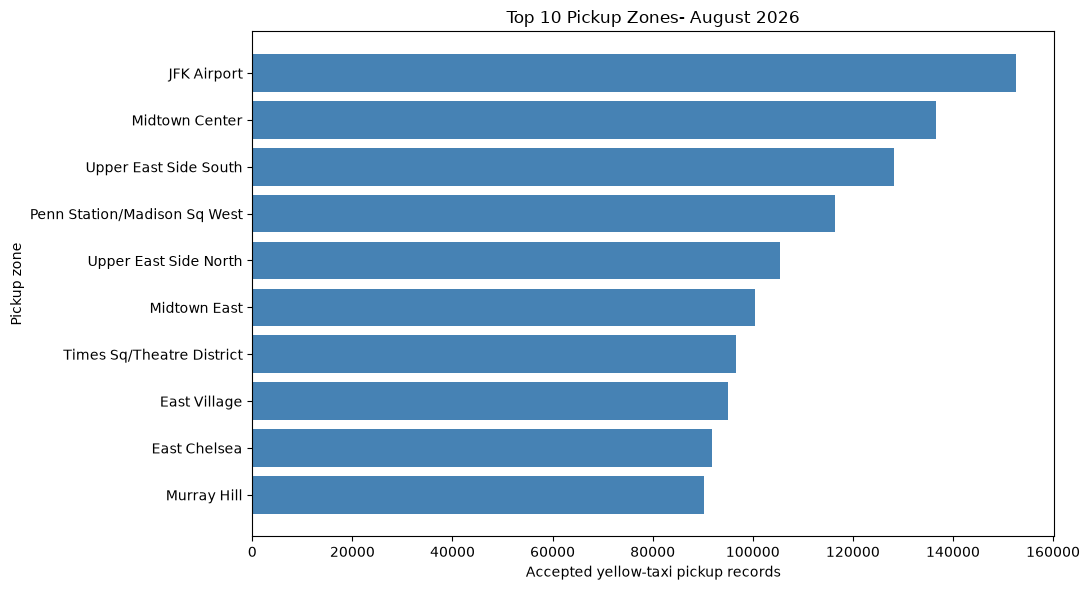

In [60]:
# creating the chart of top 10 
fig, ax = plt.subplots(figsize=(11,6))
ax.barh(
    top_zones['pickup_zone'],
    top_zones['trip_count'],
    color = 'steelblue'
)
ax.set_title('Top 10 Pickup Zones- August 2026')
ax.set_xlabel('Accepted yellow-taxi pickup records')
ax.set_ylabel('Pickup zone')

fig.tight_layout()

plt.show



In [61]:
chart_dir = project_dir / "images"

chart_dir.mkdir(
    parents=True,
    exist_ok=True
)

chart_path = chart_dir / "top_10_pickup_zones_august_2026.png"

fig.savefig(
    chart_path,
    dpi=150,
    bbox_inches="tight"
)

print("Chart saved to:", chart_path)

Chart saved to: C:\Users\Raiyan Sulemani\urban-mobility-analytics\images\top_10_pickup_zones_august_2026.png


In [62]:
#extracting the pickup date and normalising it i.e setting the time to midnight while 
#keeping the date.
accepted_named["pickup_date"] = (
    accepted_named["tpep_pickup_datetime"]
    .dt.normalize()
)

In [63]:
#counting pickups per day
daily_pickups = (
    accepted_named
    .groupby("pickup_date")
    .size()
    .reset_index(name="trip_count")
    .sort_values("pickup_date")
)

display(daily_pickups.head())

,pickup_date,trip_count
0,2026-08-01,125072
1,2026-08-02,105042
2,2026-08-03,100049
3,2026-08-04,111296
4,2026-08-05,119894


In [64]:
#checking
assert daily_pickups["trip_count"].sum() == len(accepted_named)

print("Dates represented:", len(daily_pickups))
print("First date:", daily_pickups["pickup_date"].min())
print("Last date:", daily_pickups["pickup_date"].max())

Dates represented: 31
First date: 2026-08-01 00:00:00
Last date: 2026-08-31 00:00:00


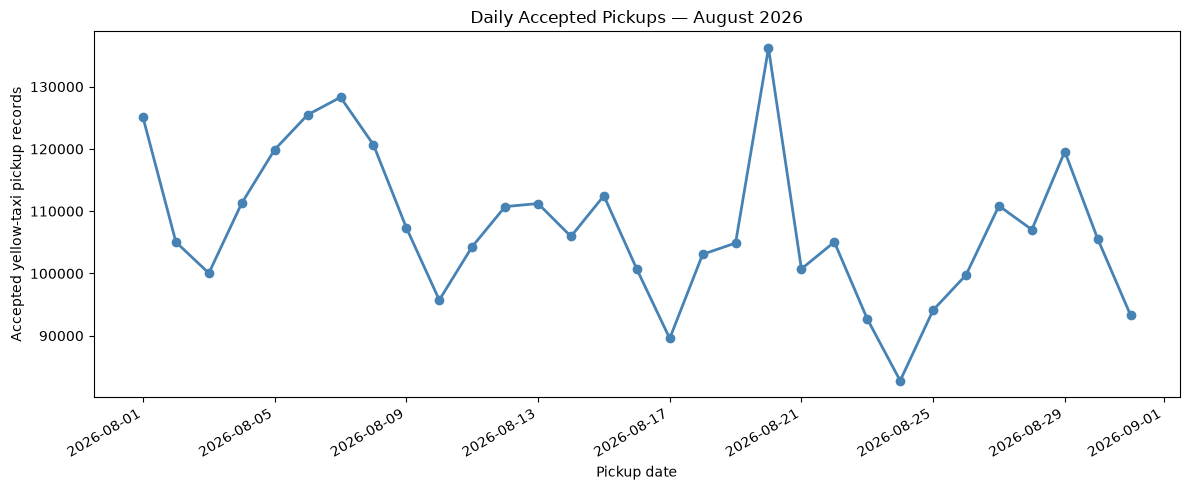

In [65]:
#drawing the daily trend
fig_daily, ax_daily = plt.subplots(figsize=(12, 5))

ax_daily.plot(
    daily_pickups["pickup_date"],
    daily_pickups["trip_count"],
    marker="o",
    color="steelblue",
    linewidth=2
)

ax_daily.set_title("Daily Accepted Pickups — August 2026")
ax_daily.set_xlabel("Pickup date")
ax_daily.set_ylabel("Accepted yellow-taxi pickup records")

fig_daily.autofmt_xdate()
fig_daily.tight_layout()

plt.show()

In [66]:
daily_chart_path = (
    chart_dir / "daily_pickups_august_2026.png"
)

fig_daily.savefig(
    daily_chart_path,
    dpi=150,
    bbox_inches="tight"
)

print("Saved:", daily_chart_path)

Saved: C:\Users\Raiyan Sulemani\urban-mobility-analytics\images\daily_pickups_august_2026.png


In [67]:
#identifying weekday for each date
daily_pickups["weekday_number"] = (
    daily_pickups["pickup_date"].dt.dayofweek
)

daily_pickups["weekday"] = (
    daily_pickups["pickup_date"].dt.day_name()
)

display(daily_pickups.head())

,pickup_date,trip_count,weekday_number,weekday
0,2026-08-01,125072,5,Saturday
1,2026-08-02,105042,6,Sunday
2,2026-08-03,100049,0,Monday
3,2026-08-04,111296,1,Tuesday
4,2026-08-05,119894,2,Wednesday


In [68]:
#calculating the weekday summary
weekday_summary = (
    daily_pickups
    .groupby(["weekday_number", "weekday"])
    .agg(
        observed_days=("pickup_date", "nunique"),
        total_pickups=("trip_count", "sum"),
        average_daily_pickups=("trip_count", "mean")
    )
    .reset_index()
    .sort_values("weekday_number")
)

display(weekday_summary)

,weekday_number,weekday,observed_days,total_pickups,average_daily_pickups
0,0,Monday,5,461412,92282.40
1,1,Tuesday,4,412789,103197.25
2,2,Wednesday,4,435276,108819.00
3,3,Thursday,4,483791,120947.75
4,4,Friday,4,442017,110504.25
5,5,Saturday,5,582873,116574.60
6,6,Sunday,5,511355,102271.00


In [69]:
assert weekday_summary["observed_days"].sum() == len(daily_pickups)

assert (
    weekday_summary["total_pickups"].sum()
    == daily_pickups["trip_count"].sum()
)

print("Weekday summary checks passed.")

Weekday summary checks passed.


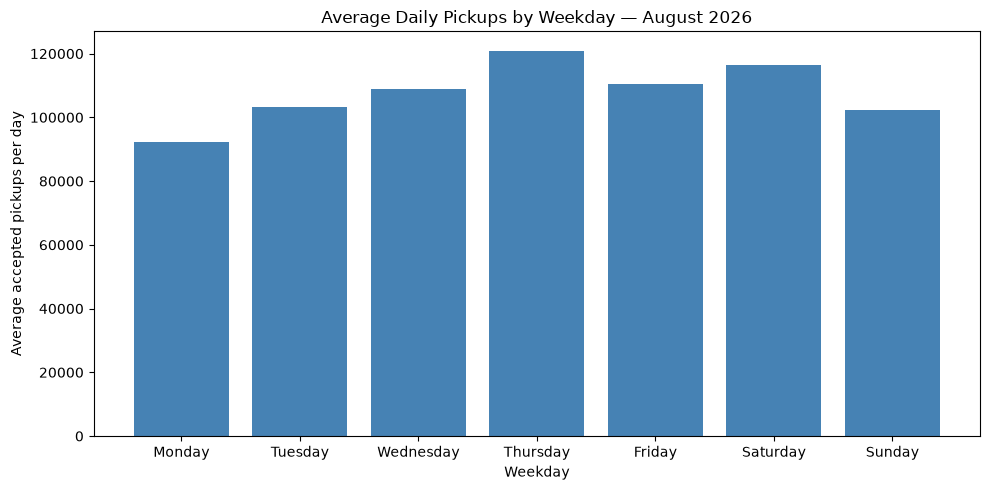

In [70]:
#plotting average daily pickups
fig_weekday, ax_weekday = plt.subplots(figsize=(10, 5))

ax_weekday.bar(
    weekday_summary["weekday"],
    weekday_summary["average_daily_pickups"],
    color="steelblue"
)

ax_weekday.set_title("Average Daily Pickups by Weekday — August 2026")
ax_weekday.set_xlabel("Weekday")
ax_weekday.set_ylabel("Average accepted pickups per day")

fig_weekday.tight_layout()

plt.show()

In [71]:
fig_weekday.savefig(
    chart_dir / "average_pickups_by_weekday_august_2026.png",
    dpi=150,
    bbox_inches="tight"
)

In [72]:
#assigning each pcikup to an hourly interval
accepted_named["pickup_hour"] = (
    accepted_named["tpep_pickup_datetime"]
    .dt.floor("h")
)

In [73]:
#counting pickups in each hourly interval
hourly_counts = (
    accepted_named
    .groupby("pickup_hour")
    .size()
)

In [74]:
#creating a complete august calendar
all_hours = pd.date_range(
    start="2026-08-01",
    end="2026-09-01",
    freq="h",
    inclusive="left"
)

hourly_pickups = (
    hourly_counts
    .reindex(all_hours, fill_value=0)
    .rename_axis("pickup_hour")
    .reset_index(name="trip_count")
)

display(hourly_pickups.head())

,pickup_hour,trip_count
0,2026-08-01 00:00:00,6303
1,2026-08-01 01:00:00,5840
2,2026-08-01 02:00:00,4043
3,2026-08-01 03:00:00,2862
4,2026-08-01 04:00:00,2114


In [75]:
assert len(hourly_pickups) == 31 * 24

assert (
    hourly_pickups["trip_count"].sum()
    == len(accepted_named)
)

print("Hourly checks passed.")

Hourly checks passed.


In [76]:
#averages by hour of day
hourly_pickups["hour_of_day"] = (
    hourly_pickups["pickup_hour"].dt.hour
)

hour_summary = (
    hourly_pickups
    .groupby("hour_of_day")
    .agg(
        observed_hours=("trip_count", "size"),
        average_pickups=("trip_count", "mean")
    )
    .reset_index()
)

display(hour_summary)

,hour_of_day,observed_hours,average_pickups
0,0,31,3684.419355
1,1,31,2647.903226
2,2,31,1803.225806
3,3,31,1256.741935
4,4,31,1001.548387
5,5,31,1038.548387
6,6,31,1835.032258
7,7,31,2839.225806
8,8,31,3937.709677
9,9,31,4346.290323


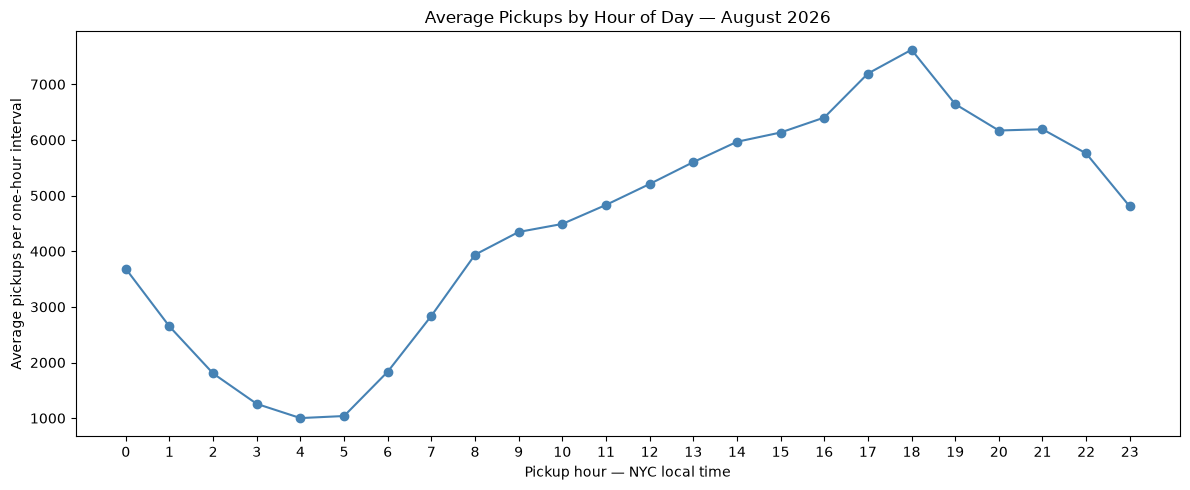

In [77]:
#plot of hourly pattern
fig_hour, ax_hour = plt.subplots(figsize=(12, 5))

ax_hour.plot(
    hour_summary["hour_of_day"],
    hour_summary["average_pickups"],
    marker="o",
    color="steelblue"
)

ax_hour.set_xticks(range(24))
ax_hour.set_title("Average Pickups by Hour of Day — August 2026")
ax_hour.set_xlabel("Pickup hour — NYC local time")
ax_hour.set_ylabel("Average pickups per one-hour interval")

fig_hour.tight_layout()

plt.show()

In [78]:
fig_hour.savefig(
    chart_dir / "average_pickups_by_hour_august_2026.png",
    dpi=150,
    bbox_inches="tight"
)

In [79]:
hourly_pickups["weekday_number"] = (
    hourly_pickups["pickup_hour"].dt.dayofweek
)

In [80]:
#weekday hour table
#neatmap
heatmap_data = hourly_pickups.pivot_table(
    index="weekday_number",
    columns="hour_of_day",
    values="trip_count",
    aggfunc="mean"
)

heatmap_data = heatmap_data.reindex(
    index=range(7),
    columns=range(24)
)

display(heatmap_data.round(1))


hour_of_day,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
weekday_number,,,,,,,,,,,,,,,,,,,,,
0,2014.4,1071.4,559.8,398.8,539.6,1148.8,2259.4,3714.4,4940.8,4891.2,...,5537.6,5448.0,5601.2,6794.0,6635.8,5341.4,5055.4,5065.6,3953.0,2859.6
1,1694.0,903.0,450.2,317.2,424.8,971.5,2145.2,3585.5,5157.8,5288.8,...,5925.2,6025.2,6161.2,6991.2,7339.2,6215.5,6176.2,6910.2,5748.2,3976.0
2,2123.0,1093.0,565.8,390.8,454.2,918.0,1953.2,3438.2,5062.2,5119.2,...,6186.5,6281.5,6581.5,7694.5,8223.5,7064.2,6552.5,7091.5,6226.2,4616.2
3,2615.5,1389.5,738.8,515.2,564.2,1012.8,2052.5,3526.0,5150.5,5224.5,...,6537.5,6592.2,7350.8,9185.2,9712.8,8533.0,7656.2,7685.5,7252.5,5601.8
4,3513.8,2227.8,1405.8,882.8,754.0,1109.8,1971.0,2847.8,3766.5,4145.5,...,6094.2,6372.5,6628.0,7135.2,8751.8,7754.5,6517.2,5971.8,6464.5,6469.2
5,6143.2,5206.6,3853.6,2723.6,1775.6,968.8,1332.6,1682.2,2223.8,3315.2,...,5766.0,6313.6,6716.4,7067.4,7528.6,6945.2,6359.8,6240.2,7029.6,7314.4
6,6728.8,5648.4,4238.2,2984.6,2136.6,1111.8,1287.6,1488.6,1939.6,2918.2,...,5893.4,6048.0,5998.0,5928.0,5861.0,5250.6,5312.4,4959.2,4162.8,3078.8


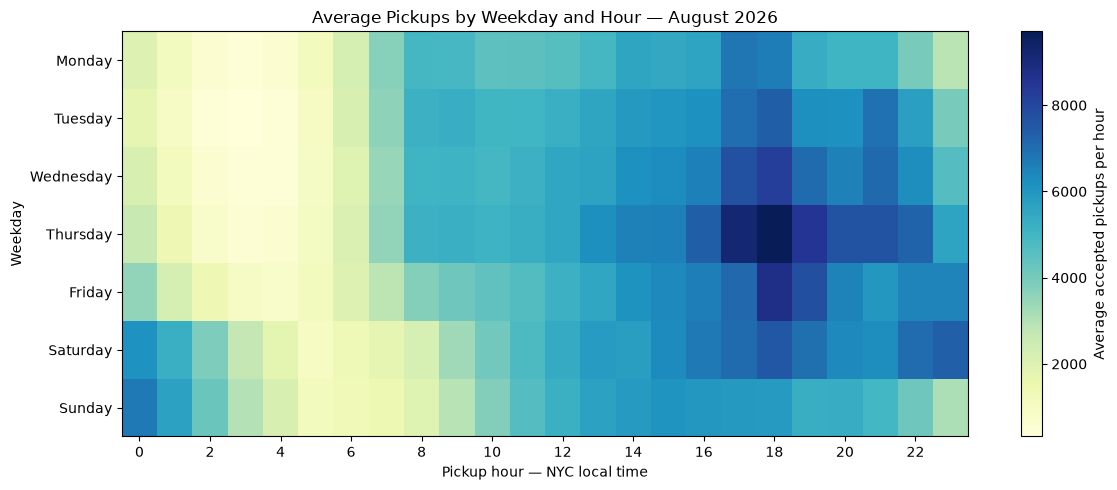

In [81]:
#colored table, heat map

weekday_names = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

fig_heatmap, ax_heatmap = plt.subplots(figsize=(12, 5))

heat = ax_heatmap.imshow(
    heatmap_data,
    aspect="auto",
    cmap="YlGnBu"
)

ax_heatmap.set_yticks(range(7))
ax_heatmap.set_yticklabels(weekday_names)

ax_heatmap.set_xticks(range(0, 24, 2))

ax_heatmap.set_title(
    "Average Pickups by Weekday and Hour — August 2026"
)
ax_heatmap.set_xlabel("Pickup hour — NYC local time")
ax_heatmap.set_ylabel("Weekday")

colorbar = fig_heatmap.colorbar(heat, ax=ax_heatmap)
colorbar.set_label("Average accepted pickups per hour")

fig_heatmap.tight_layout()

plt.show()

In [82]:
fig_heatmap.savefig(
    chart_dir / "weekday_hour_heatmap_august_2026.png",
    dpi=150,
    bbox_inches="tight"
)

In [83]:
#count of accepted pickups by borough
borough_counts = (
    accepted_named
    .groupby("pickup_borough", dropna=False)
    .size()
    .reset_index(name="accepted_pickups")
)
 
borough_counts["pickup_share_pct"] = (
    borough_counts["accepted_pickups"]
    / len(accepted_named)
    * 100
) 

display(borough_counts)

,pickup_borough,accepted_pickups,pickup_share_pct
0,Bronx,15043,0.451808
1,Brooklyn,102409,3.075795
2,EWR,478,0.014356
3,Manhattan,2894669,86.939712
4,Queens,316552,9.507456
5,Staten Island,362,0.010872


In [84]:
#statistics from screened trips
borough_metrics = (
    metric_named
    .groupby("pickup_borough", dropna=False)
    .agg(
        screened_trips=("fare_amount", "size"),
        average_fare_usd=("fare_amount", "mean"),
        average_duration_minutes=("duration_minutes", "mean"),
        average_distance_miles=("trip_distance", "mean")
    )
    .reset_index()
)

display(borough_metrics)

,pickup_borough,screened_trips,average_fare_usd,average_duration_minutes,average_distance_miles
0,Bronx,13750,30.200490,23.250115,7.275731
1,Brooklyn,95266,29.906000,23.992205,5.657185
2,EWR,18,90.882778,25.653704,12.636667
3,Manhattan,2744060,17.577081,15.248555,2.802011
4,Queens,295892,49.635000,33.403293,11.477697
5,Staten Island,313,33.609840,24.365708,10.115783


In [85]:
borough_summary = (
    borough_counts
    .merge(
        borough_metrics,
        on="pickup_borough",
        how="left",
        validate="one_to_one"
    )
    .sort_values("accepted_pickups", ascending=False)
)

In [86]:
borough_summary["screened_trips"] = (
    borough_summary["screened_trips"]
    .fillna(0)
    .astype(int)
)

In [87]:
assert (
    borough_summary["accepted_pickups"].sum()
    == len(accepted_named)
)

assert (
    borough_summary["screened_trips"].sum()
    == len(metric_named)
)

print("Borough totals match both source datasets.")

Borough totals match both source datasets.


In [88]:
display(
    borough_summary.style.format({
        "accepted_pickups": "{:,.0f}",
        "pickup_share_pct": "{:.2f}%",
        "screened_trips": "{:,.0f}",
        "average_fare_usd": "${:.2f}",
        "average_duration_minutes": "{:.2f}",
        "average_distance_miles": "{:.2f}"
    }, na_rep="Not available")
)

,pickup_borough,accepted_pickups,pickup_share_pct,screened_trips,average_fare_usd,average_duration_minutes,average_distance_miles
3,Manhattan,"2,894,669",86.94%,"2,744,060",$17.58,15.25,2.80
4,Queens,"316,552",9.51%,"295,892",$49.63,33.40,11.48
1,Brooklyn,"102,409",3.08%,"95,266",$29.91,23.99,5.66
0,Bronx,"15,043",0.45%,"13,750",$30.20,23.25,7.28
2,EWR,478,0.01%,18,$90.88,25.65,12.64
5,Staten Island,362,0.01%,313,$33.61,24.37,10.12


In [89]:
#date columns
accepted_named["pickup_date"] = (
    accepted_named["tpep_pickup_datetime"].dt.normalize()
)

metric_named["pickup_date"] = (
    metric_named["tpep_pickup_datetime"].dt.normalize()
)

In [90]:
#count of accepted pickups by date and zone
daily_zone_counts = (
    accepted_named
    .groupby(["pickup_date", "PULocationID"])
    .size()
    .reset_index(name="pickups")
)

In [91]:
#summarising the screened records
daily_zone_metrics = (
    metric_named
    .groupby(["pickup_date", "PULocationID"])
    .agg(
        metric_trips=("fare_amount", "size"),
        fare_sum=("fare_amount", "sum"),
        recorded_total_sum=("total_amount", "sum"),
        duration_sum=("duration_minutes", "sum"),
        distance_sum=("trip_distance", "sum")
    )
    .reset_index()
)

In [92]:
#combining both summaries
fact_daily_zone = daily_zone_counts.merge(
    daily_zone_metrics,
    on=["pickup_date", "PULocationID"],
    how="left",
    validate="one_to_one"
)

In [93]:
#filling the missed counts and sum with zero
metric_columns = [
    "metric_trips",
    "fare_sum",
    "recorded_total_sum",
    "duration_sum",
    "distance_sum"
]

fact_daily_zone[metric_columns] = (
    fact_daily_zone[metric_columns].fillna(0)
)

fact_daily_zone["metric_trips"] = (
    fact_daily_zone["metric_trips"].astype(int)
)

In [94]:
#renaming the columns ans verifying the table
fact_daily_zone = (
    fact_daily_zone
    .rename(columns={
        "pickup_date": "date",
        "PULocationID": "pickup_zone_id"
    })
    .sort_values(["date", "pickup_zone_id"])
)

assert not fact_daily_zone.duplicated(
    ["date", "pickup_zone_id"]
).any()

assert fact_daily_zone["pickups"].sum() == len(accepted_named)

assert fact_daily_zone["metric_trips"].sum() == len(metric_named)

display(fact_daily_zone.head(10))

,date,pickup_zone_id,pickups,metric_trips,fare_sum,recorded_total_sum,duration_sum,distance_sum
0,2026-08-01,1,19,0,0.00,0.00,0.000000,0.00
1,2026-08-01,3,6,6,171.47,225.13,107.733333,42.12
2,2026-08-01,4,900,882,16749.58,22525.06,15277.983333,2910.23
3,2026-08-01,6,1,1,0.01,23.39,32.516667,7.15
4,2026-08-01,7,322,315,8342.65,10156.85,7204.683333,1730.26
5,2026-08-01,8,3,3,96.44,114.90,77.433333,18.46
6,2026-08-01,9,1,1,38.40,50.61,26.216667,12.91
7,2026-08-01,10,33,29,2253.51,2688.99,1246.566667,390.52
8,2026-08-01,12,88,81,2166.55,2853.62,1786.750000,354.10
9,2026-08-01,13,705,690,16545.64,22184.43,12549.133333,2886.23


In [95]:
processed_dir = project_dir / "data" / "processed"

processed_dir.mkdir(parents=True, exist_ok=True)

fact_daily_zone.to_csv(
    processed_dir / "fact_daily_zone.csv",
    index=False,
    date_format="%Y-%m-%d"
)

print("Saved to:", processed_dir / "fact_daily_zone.csv")

Saved to: C:\Users\Raiyan Sulemani\urban-mobility-analytics\data\processed\fact_daily_zone.csv


In [96]:
#zone lokup table
dim_zone = (
    pickup_lookup
    .loc[
        pickup_lookup["PULocationID"].isin(known_zone_ids),
        ["PULocationID", "pickup_zone", "pickup_borough"]
    ]
    .rename(columns={
        "PULocationID": "pickup_zone_id"
    })
    .sort_values("pickup_zone_id")
    .reset_index(drop=True)
)

display(dim_zone.head())

,pickup_zone_id,pickup_zone,pickup_borough
0,1,Newark Airport,EWR
1,2,Jamaica Bay,Queens
2,3,Allerton/Pelham Gardens,Bronx
3,4,Alphabet City,Manhattan
4,5,Arden Heights,Staten Island


In [97]:
#date lookup table
dim_date = pd.DataFrame({
    "date": pd.date_range(
        start="2026-08-01",
        end="2026-08-31",
        freq="D"
    )
})

display(dim_date.head())

,date
0,2026-08-01
1,2026-08-02
2,2026-08-03
3,2026-08-04
4,2026-08-05


In [98]:
#adding useful calendar column
dim_date["year"] = dim_date["date"].dt.year
dim_date["month_number"] = dim_date["date"].dt.month
dim_date["month_name"] = dim_date["date"].dt.month_name()
dim_date["day_of_month"] = dim_date["date"].dt.day

dim_date["weekday_number"] = dim_date["date"].dt.dayofweek
dim_date["weekday_name"] = dim_date["date"].dt.day_name()

dim_date["is_weekend"] = (
    dim_date["weekday_number"] >= 5
)

display(dim_date.head())

,date,year,month_number,month_name,day_of_month,weekday_number,weekday_name,is_weekend
0,2026-08-01,2026,8,August,1,5,Saturday,True
1,2026-08-02,2026,8,August,2,6,Sunday,True
2,2026-08-03,2026,8,August,3,0,Monday,False
3,2026-08-04,2026,8,August,4,1,Tuesday,False
4,2026-08-05,2026,8,August,5,2,Wednesday,False


In [99]:
assert dim_zone["pickup_zone_id"].is_unique
assert dim_date["date"].is_unique
assert len(dim_date) == 31

assert fact_daily_zone["pickup_zone_id"].isin(
    dim_zone["pickup_zone_id"]
).all()

assert fact_daily_zone["date"].isin(
    dim_date["date"]
).all()

print("All lookup-table checks passed.")


All lookup-table checks passed.


In [100]:
#exporting both lookup tables
dim_zone.to_csv(
    processed_dir / "dim_zone.csv",
    index=False
)

dim_date.to_csv(
    processed_dir / "dim_date.csv",
    index=False,
    date_format="%Y-%m-%d"
)

print("Saved:", processed_dir / "dim_zone.csv")
print("Saved:", processed_dir / "dim_date.csv")

Saved: C:\Users\Raiyan Sulemani\urban-mobility-analytics\data\processed\dim_zone.csv
Saved: C:\Users\Raiyan Sulemani\urban-mobility-analytics\data\processed\dim_date.csv


## 4. SQL Analysis

I loaded daily pickup aggregates and lookup tables into SQLite.

The queries use joins and aggregations to compare zones and calendar
groups. Window functions calculate day-to-day changes and a seven-day
moving average.

In [101]:
#creation of SQLite database
#creating and connecting to the database
import sqlite3

database_dir = project_dir / "data"
database_dir.mkdir(parents=True, exist_ok=True)

database_path = database_dir / "urban_mobility.db"

conn = sqlite3.connect(database_path)

print("Database location:", database_path)

Database location: C:\Users\Raiyan Sulemani\urban-mobility-analytics\data\urban_mobility.db


In [102]:
#preparing the dates for SQL
dim_date_sql = dim_date.copy()
fact_daily_zone_sql = fact_daily_zone.copy()

dim_date_sql["date"] = (
    dim_date_sql["date"].dt.strftime("%Y-%m-%d")
)

fact_daily_zone_sql["date"] = (
    fact_daily_zone_sql["date"].dt.strftime("%Y-%m-%d")
)

display(dim_date_sql.head())

,date,year,month_number,month_name,day_of_month,weekday_number,weekday_name,is_weekend
0,2026-08-01,2026,8,August,1,5,Saturday,True
1,2026-08-02,2026,8,August,2,6,Sunday,True
2,2026-08-03,2026,8,August,3,0,Monday,False
3,2026-08-04,2026,8,August,4,1,Tuesday,False
4,2026-08-05,2026,8,August,5,2,Wednesday,False


In [103]:
#loading three tables
dim_zone.to_sql(
    name="dim_zone",
    con=conn,
    if_exists="replace",
    index=False
)

dim_date_sql.to_sql(
    name="dim_date",
    con=conn,
    if_exists="replace",
    index=False
)

fact_daily_zone_sql.to_sql(
    name="fact_daily_zone",
    con=conn,
    if_exists="replace",
    index=False
)

print("All three tables loaded.")

All three tables loaded.


In [104]:
table_query = """
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name;
"""

database_tables = pd.read_sql_query(
    table_query,
    conn
)

display(database_tables)

,name
0,dim_date
1,dim_zone
2,fact_daily_zone


In [105]:
totals_query = """
SELECT
    COUNT(*) AS date_zone_rows,
    SUM(pickups) AS accepted_pickups,
    SUM(metric_trips) AS screened_trips
FROM fact_daily_zone;
"""

sql_totals = pd.read_sql_query(
    totals_query,
    conn
)

display(sql_totals)


,date_zone_rows,accepted_pickups,screened_trips
0,7368,3329513,3149299


In [106]:
#verifying if the loading preserved our totals
assert int(sql_totals.loc[0, "date_zone_rows"]) == len(
    fact_daily_zone
)

assert int(sql_totals.loc[0, "accepted_pickups"]) == len(
    accepted_named
)

assert int(sql_totals.loc[0, "screened_trips"]) == len(
    metric_named
)

print("SQL totals match the Pandas totals.")

SQL totals match the Pandas totals.


In [107]:

join_preview_query = """
SELECT
    f.date,
    f.pickup_zone_id,
    z.pickup_zone,
    z.pickup_borough,
    f.pickups
FROM fact_daily_zone AS f
LEFT JOIN dim_zone AS z
    ON f.pickup_zone_id = z.pickup_zone_id
ORDER BY
    f.date,
    f.pickup_zone_id
LIMIT 10;
"""

join_preview = pd.read_sql_query(
    join_preview_query,
    conn
)

display(join_preview)

,date,pickup_zone_id,pickup_zone,pickup_borough,pickups
0,2026-08-01,1,Newark Airport,EWR,19
1,2026-08-01,3,Allerton/Pelham Gardens,Bronx,6
2,2026-08-01,4,Alphabet City,Manhattan,900
3,2026-08-01,6,Arrochar/Fort Wadsworth,Staten Island,1
4,2026-08-01,7,Astoria,Queens,322
5,2026-08-01,8,Astoria Park,Queens,3
6,2026-08-01,9,Auburndale,Queens,1
7,2026-08-01,10,Baisley Park,Queens,33
8,2026-08-01,12,Battery Park,Manhattan,88
9,2026-08-01,13,Battery Park City,Manhattan,705


In [108]:
#10 busiest zone 
top_zones_query = """
SELECT
    z.pickup_zone_id,
    z.pickup_zone,
    z.pickup_borough,
    SUM(f.pickups) AS accepted_pickups
FROM fact_daily_zone AS f
LEFT JOIN dim_zone AS z
    ON f.pickup_zone_id = z.pickup_zone_id
GROUP BY
    z.pickup_zone_id,
    z.pickup_zone,
    z.pickup_borough
ORDER BY accepted_pickups DESC
LIMIT 10;
"""

sql_top_zones = pd.read_sql_query(
    top_zones_query,
    conn
)

display(sql_top_zones)

,pickup_zone_id,pickup_zone,pickup_borough,accepted_pickups
0,132,JFK Airport,Queens,152581
1,161,Midtown Center,Manhattan,136670
2,237,Upper East Side South,Manhattan,128140
3,186,Penn Station/Madison Sq West,Manhattan,116496
4,236,Upper East Side North,Manhattan,105365
5,162,Midtown East,Manhattan,100464
6,230,Times Sq/Theatre District,Manhattan,96740
7,79,East Village,Manhattan,95137
8,68,East Chelsea,Manhattan,91896
9,170,Murray Hill,Manhattan,90180


In [109]:
#adding average fair and duration
zone_metrics_query = """
SELECT
    z.pickup_zone_id,
    z.pickup_zone,
    z.pickup_borough,

    SUM(f.pickups) AS accepted_pickups,
    SUM(f.metric_trips) AS screened_trips,

    ROUND(
        1.0 * SUM(f.fare_sum)
        / NULLIF(SUM(f.metric_trips), 0),
        2
    ) AS average_fare_usd,

    ROUND(
        1.0 * SUM(f.duration_sum)
        / NULLIF(SUM(f.metric_trips), 0),
        2
    ) AS average_duration_minutes

FROM fact_daily_zone AS f
LEFT JOIN dim_zone AS z
    ON f.pickup_zone_id = z.pickup_zone_id

GROUP BY
    z.pickup_zone_id,
    z.pickup_zone,
    z.pickup_borough

ORDER BY accepted_pickups DESC
LIMIT 10;
"""

sql_zone_metrics = pd.read_sql_query(
    zone_metrics_query,
    conn
)

display(sql_zone_metrics)

,pickup_zone_id,pickup_zone,pickup_borough,accepted_pickups,screened_trips,average_fare_usd,average_duration_minutes
0,132,JFK Airport,Queens,152581,145131,60.38,40.43
1,161,Midtown Center,Manhattan,136670,130468,17.21,15.22
2,237,Upper East Side South,Manhattan,128140,122335,13.70,12.12
3,186,Penn Station/Madison Sq West,Manhattan,116496,111718,17.88,16.96
4,236,Upper East Side North,Manhattan,105365,99788,14.67,12.58
5,162,Midtown East,Manhattan,100464,95728,16.31,14.44
6,230,Times Sq/Theatre District,Manhattan,96740,92438,20.10,16.93
7,79,East Village,Manhattan,95137,90759,17.89,15.77
8,68,East Chelsea,Manhattan,91896,86937,19.05,17.24
9,170,Murray Hill,Manhattan,90180,85337,16.64,14.83


In [110]:
#check the joined totals
join_check_query = """
SELECT
    SUM(f.pickups) AS joined_pickups,

    SUM(
        CASE
            WHEN z.pickup_zone_id IS NULL THEN f.pickups
            ELSE 0
        END
    ) AS unmatched_pickups

FROM fact_daily_zone AS f
LEFT JOIN dim_zone AS z
    ON f.pickup_zone_id = z.pickup_zone_id;
    
"""

join_check = pd.read_sql_query(
    join_check_query,
    conn
)

assert int(join_check.loc[0, "joined_pickups"]) == len(
    accepted_named
)

assert int(join_check.loc[0, "unmatched_pickups"]) == 0

display(join_check)

print("The join preserved pickup totals, and every zone matched.")

,joined_pickups,unmatched_pickups
0,3329513,0


The join preserved pickup totals, and every zone matched.


In [111]:
sql_zone_metrics.to_csv(
    processed_dir / "sql_top_10_zone_metrics.csv",
    index=False
)

print(
    "Saved:",
    processed_dir / "sql_top_10_zone_metrics.csv"
)

Saved: C:\Users\Raiyan Sulemani\urban-mobility-analytics\data\processed\sql_top_10_zone_metrics.csv


In [112]:
#one pickup total per date
daily_sql_query = """
SELECT
    d.date,
    d.weekday_name,
    d.is_weekend,
    COALESCE(SUM(f.pickups), 0) AS daily_pickups
FROM dim_date AS d
LEFT JOIN fact_daily_zone AS f
    ON d.date = f.date
GROUP BY
    d.date,
    d.weekday_name,
    d.is_weekend
ORDER BY d.date;
"""

sql_daily_pickups = pd.read_sql_query(
    daily_sql_query,
    conn
)

display(sql_daily_pickups.head(10))

,date,weekday_name,is_weekend,daily_pickups
0,2026-08-01,Saturday,1,125072
1,2026-08-02,Sunday,1,105042
2,2026-08-03,Monday,0,100049
3,2026-08-04,Tuesday,0,111296
4,2026-08-05,Wednesday,0,119894
5,2026-08-06,Thursday,0,125476
6,2026-08-07,Friday,0,128298
7,2026-08-08,Saturday,1,120677
8,2026-08-09,Sunday,1,107347
9,2026-08-10,Monday,0,95738


In [113]:
#COMMON TABLE EXPRESSION (CTE)
day_type_query = """
WITH daily_totals AS (
    SELECT
        d.date,
        d.is_weekend,
        COALESCE(SUM(f.pickups), 0) AS daily_pickups
    FROM dim_date AS d
    LEFT JOIN fact_daily_zone AS f
        ON d.date = f.date
    GROUP BY
        d.date,
        d.is_weekend
)

SELECT
    CASE
        WHEN is_weekend = 1 THEN 'Weekend'
        ELSE 'Weekday'
    END AS day_type,

    COUNT(*) AS calendar_days,
    SUM(daily_pickups) AS total_pickups,
    ROUND(AVG(daily_pickups), 2) AS average_daily_pickups

FROM daily_totals
GROUP BY is_weekend
ORDER BY is_weekend;
"""

sql_day_type = pd.read_sql_query(
    day_type_query,
    conn
)

display(sql_day_type)

,day_type,calendar_days,total_pickups,average_daily_pickups
0,Weekday,21,2235285,106442.14
1,Weekend,10,1094228,109422.80


In [114]:
assert len(sql_daily_pickups) == 31

assert sql_day_type["calendar_days"].sum() == 31

assert sql_day_type["total_pickups"].sum() == len(
    accepted_named
)

print("Calendar days and pickup totals match.")

Calendar days and pickup totals match.


In [115]:
#percentage difference on weekdays and weekends
day_type_averages = sql_day_type.set_index(
    "day_type"
)["average_daily_pickups"]

weekday_average = day_type_averages.loc["Weekday"]
weekend_average = day_type_averages.loc["Weekend"]

if weekday_average > 0:
    weekend_difference_pct = (
        (weekend_average - weekday_average)
        / weekday_average
        * 100
    )

    print(
        f"Weekend average daily pickups were "
        f"{weekend_difference_pct:+.2f}% "
        f"relative to weekdays."
    )
else:
    print(
        "Percentage difference cannot be calculated "
        "because the weekday average is zero."
    )

Weekend average daily pickups were +2.80% relative to weekdays.


In [116]:
sql_day_type.to_csv(
    processed_dir / "sql_weekday_weekend_summary.csv",
    index=False
)

print("Weekday–weekend summary saved.")

Weekday–weekend summary saved.


In [117]:
daily_lag_query = """
WITH daily_totals AS (
    SELECT
        d.date,
        COALESCE(SUM(f.pickups), 0) AS daily_pickups
    FROM dim_date AS d
    LEFT JOIN fact_daily_zone AS f
        ON d.date = f.date
    GROUP BY d.date
)

SELECT
    date,
    daily_pickups,

    LAG(daily_pickups, 1) OVER (
        ORDER BY date
    ) AS previous_day_pickups

FROM daily_totals
ORDER BY date;
"""

sql_daily_lag = pd.read_sql_query(
    daily_lag_query,
    conn
)

display(sql_daily_lag.head(10))

,date,daily_pickups,previous_day_pickups
0,2026-08-01,125072,NaN
1,2026-08-02,105042,125072.0
2,2026-08-03,100049,105042.0
3,2026-08-04,111296,100049.0
4,2026-08-05,119894,111296.0
5,2026-08-06,125476,119894.0
6,2026-08-07,128298,125476.0
7,2026-08-08,120677,128298.0
8,2026-08-09,107347,120677.0
9,2026-08-10,95738,107347.0


In [118]:
#absolute and percentage changes
daily_change_query = """
WITH daily_totals AS (
    SELECT
        d.date,
        COALESCE(SUM(f.pickups), 0) AS daily_pickups
    FROM dim_date AS d
    LEFT JOIN fact_daily_zone AS f
        ON d.date = f.date
    GROUP BY d.date
),

daily_with_previous AS (
    SELECT
        date,
        daily_pickups,

        LAG(daily_pickups, 1) OVER (
            ORDER BY date
        ) AS previous_day_pickups

    FROM daily_totals
)

SELECT
    date,
    daily_pickups,
    previous_day_pickups,

    daily_pickups - previous_day_pickups
        AS pickup_change,

    ROUND(
        100.0 * (daily_pickups - previous_day_pickups)
        / NULLIF(previous_day_pickups, 0),
        2
    ) AS pickup_change_pct

FROM daily_with_previous
ORDER BY date;
"""

sql_daily_change = pd.read_sql_query(
    daily_change_query,
    conn
)

display(sql_daily_change.head(10))

,date,daily_pickups,previous_day_pickups,pickup_change,pickup_change_pct
0,2026-08-01,125072,NaN,NaN,NaN
1,2026-08-02,105042,125072.0,-20030.0,-16.01
2,2026-08-03,100049,105042.0,-4993.0,-4.75
3,2026-08-04,111296,100049.0,11247.0,11.24
4,2026-08-05,119894,111296.0,8598.0,7.73
5,2026-08-06,125476,119894.0,5582.0,4.66
6,2026-08-07,128298,125476.0,2822.0,2.25
7,2026-08-08,120677,128298.0,-7621.0,-5.94
8,2026-08-09,107347,120677.0,-13330.0,-11.05
9,2026-08-10,95738,107347.0,-11609.0,-10.81


In [119]:
comparable_days = sql_daily_change.dropna(
    subset=["pickup_change"]
)

largest_increases = comparable_days.nlargest(
    5,
    "pickup_change"
)

largest_decreases = comparable_days.nsmallest(
    5,
    "pickup_change"
)

print("Five largest changes, from highest:")
display(largest_increases)

print("Five largest changes, from lowest:")
display(largest_decreases)

Five largest changes, from highest:


,date,daily_pickups,previous_day_pickups,pickup_change,pickup_change_pct
19,2026-08-20,136216,104888.0,31328.0,29.87
17,2026-08-18,103077,89566.0,13511.0,15.08
28,2026-08-29,119583,107040.0,12543.0,11.72
24,2026-08-25,94107,82776.0,11331.0,13.69
3,2026-08-04,111296,100049.0,11247.0,11.24


Five largest changes, from lowest:


,date,daily_pickups,previous_day_pickups,pickup_change,pickup_change_pct
20,2026-08-21,100731,136216.0,-35485.0,-26.05
1,2026-08-02,105042,125072.0,-20030.0,-16.01
29,2026-08-30,105559,119583.0,-14024.0,-11.73
8,2026-08-09,107347,120677.0,-13330.0,-11.05
22,2026-08-23,92705,105057.0,-12352.0,-11.76


In [120]:
expected_change = sql_daily_change["daily_pickups"].diff()

pd.testing.assert_series_equal(
    sql_daily_change["pickup_change"],
    expected_change,
    check_names=False,
    check_dtype=False
)

print("SQL day-to-day changes match Pandas.")

SQL day-to-day changes match Pandas.


In [121]:
sql_daily_change.to_csv(
    processed_dir / "sql_daily_pickup_changes.csv",
    index=False
)

print("Daily pickup changes saved.")

Daily pickup changes saved.


In [122]:
#moving 7 day average 
moving_average_query = """
WITH daily_totals AS (
    SELECT
        d.date,
        COALESCE(SUM(f.pickups), 0) AS daily_pickups
    FROM dim_date AS d
    LEFT JOIN fact_daily_zone AS f
        ON d.date = f.date
    GROUP BY d.date
),

rolling_summary AS (
    SELECT
        date,
        daily_pickups,

        COUNT(*) OVER (
            ORDER BY date
            ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
        ) AS days_in_window,

        AVG(daily_pickups) OVER (
            ORDER BY date
            ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
        ) AS rolling_average

    FROM daily_totals
)

SELECT
    date,
    daily_pickups,

    CASE
        WHEN days_in_window = 7 THEN rolling_average
        ELSE NULL
    END AS moving_average_7d

FROM rolling_summary
ORDER BY date;
"""

sql_daily_trend = pd.read_sql_query(
    moving_average_query,
    conn
)

display(sql_daily_trend.head(10))

,date,daily_pickups,moving_average_7d
0,2026-08-01,125072,NaN
1,2026-08-02,105042,NaN
2,2026-08-03,100049,NaN
3,2026-08-04,111296,NaN
4,2026-08-05,119894,NaN
5,2026-08-06,125476,NaN
6,2026-08-07,128298,116446.714286
7,2026-08-08,120677,115818.857143
8,2026-08-09,107347,116148.142857
9,2026-08-10,95738,115532.285714


In [123]:
sql_daily_trend["date"] = pd.to_datetime(
    sql_daily_trend["date"]
)

expected_moving_average = (
    sql_daily_trend["daily_pickups"]
    .rolling(window=7, min_periods=7)
    .mean()
)

pd.testing.assert_series_equal(
    sql_daily_trend["moving_average_7d"],
    expected_moving_average,
    check_names=False,
    check_dtype=False
)

print("SQL and Pandas moving averages match.")

SQL and Pandas moving averages match.


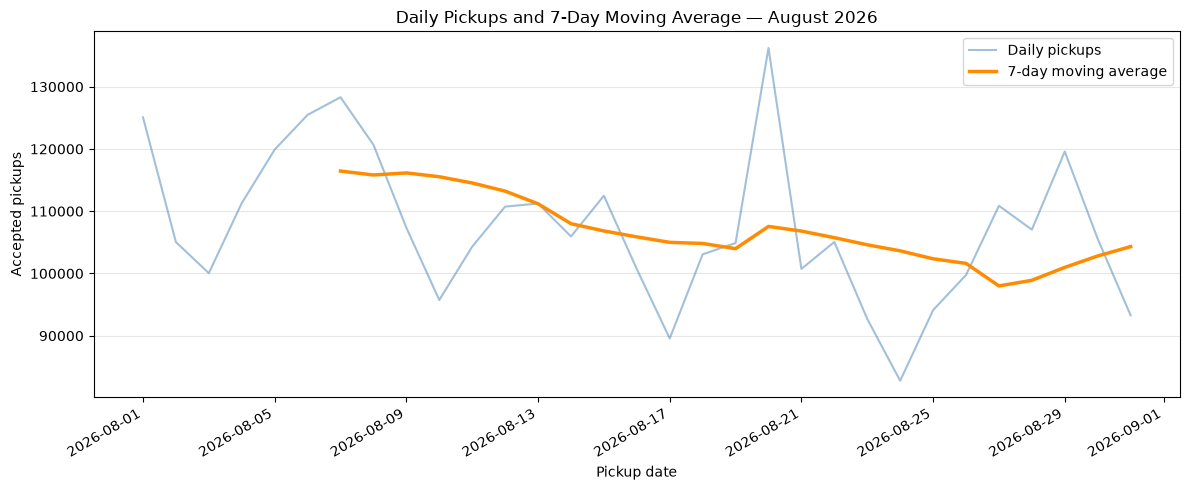

In [124]:
#plot of daily pickups and the moving average
fig_trend, ax_trend = plt.subplots(figsize=(12, 5))

ax_trend.plot(
    sql_daily_trend["date"],
    sql_daily_trend["daily_pickups"],
    label="Daily pickups",
    color="steelblue",
    alpha=0.5,
    linewidth=1.5
)

ax_trend.plot(
    sql_daily_trend["date"],
    sql_daily_trend["moving_average_7d"],
    label="7-day moving average",
    color="darkorange",
    linewidth=2.5
)

ax_trend.set_title(
    "Daily Pickups and 7-Day Moving Average — August 2026"
)
ax_trend.set_xlabel("Pickup date")
ax_trend.set_ylabel("Accepted pickups")
ax_trend.legend()
ax_trend.grid(axis="y", alpha=0.3)

fig_trend.autofmt_xdate()
fig_trend.tight_layout()

plt.show()

In [125]:
chart_dir.mkdir(parents=True, exist_ok=True)

fig_trend.savefig(
    chart_dir / "daily_pickups_7day_average_august_2026.png",
    dpi=150,
    bbox_inches="tight"
)

sql_daily_trend.to_csv(
    processed_dir / "sql_daily_pickup_trend.csv",
    index=False,
    date_format="%Y-%m-%d"
)

print("Trend chart and CSV saved.")

Trend chart and CSV saved.


In [126]:
print("Folder:", processed_dir.resolve())
print("Folder exists:", processed_dir.exists())

for file in processed_dir.glob("*.csv"):
    print(file.name)

Folder: C:\Users\Raiyan Sulemani\urban-mobility-analytics\data\processed
Folder exists: True
baseline_hourly_predictions.csv
baseline_vs_tree_predictions.csv
baseline_vs_tree_scores.csv
dim_date.csv
dim_zone.csv
fact_daily_zone.csv
hourly_model_data.csv
selected_approach_predictions.csv
selected_approach_summary.csv
selected_tree_errors_by_hour.csv
selected_tree_largest_errors.csv
selected_tree_test_predictions.csv
selected_tree_test_scores.csv
sql_daily_pickup_changes.csv
sql_daily_pickup_trend.csv
sql_top_10_zone_metrics.csv
sql_weekday_weekend_summary.csv


In [127]:
reference_metrics = pd.Series({
    "Accepted Pickups": len(accepted_named),

    "Screened Trips": len(metric_named),

    "Average Fare USD":
        metric_named["fare_amount"].mean(),

    "Average Duration Minutes":
        metric_named["duration_minutes"].mean(),

    "Screening Coverage":
        len(metric_named) / len(accepted_named)
})

display(reference_metrics)

Accepted Pickups            3.329513e+06
Screened Trips              3.149299e+06
Average Fare USD            2.101915e+01
Average Duration Minutes    1.725468e+01
Screening Coverage          9.458738e-01
dtype: float64

In [128]:
display(
    sql_daily_pickups[["date", "daily_pickups"]].head(7)
)

,date,daily_pickups
0,2026-08-01,125072
1,2026-08-02,105042
2,2026-08-03,100049
3,2026-08-04,111296
4,2026-08-05,119894
5,2026-08-06,125476
6,2026-08-07,128298


## 5. Forecasting Problem and Feature Engineering

The target is the number of accepted pickups during a specified hour,
aggregated across recognised pickup zones.

Features include pickup counts from 1, 24 and 168 hours earlier,
past-only rolling averages, and calendar information for the target hour.

Rolling features are shifted before averaging to exclude the target
hour's actual count. Calendar features are known in advance.

This is a historical one-hour-ahead forecasting exercise.

In [129]:
forecast_data = (
    hourly_pickups[["pickup_hour", "trip_count"]]
    .copy()
    .sort_values("pickup_hour")
    .reset_index(drop=True)
    .rename(columns={
        "trip_count": "pickups"
    })
)

display(forecast_data.head())

,pickup_hour,pickups
0,2026-08-01 00:00:00,6303
1,2026-08-01 01:00:00,5840
2,2026-08-01 02:00:00,4043
3,2026-08-01 03:00:00,2862
4,2026-08-01 04:00:00,2114


In [130]:
expected_hours = pd.date_range(
    start="2026-08-01",
    end="2026-09-01",
    freq="h",
    inclusive="left" #includes august1 but excludes september 1
)

assert forecast_data["pickup_hour"].is_unique

assert forecast_data["pickup_hour"].tolist() == (
    expected_hours.tolist()
)

assert forecast_data["pickups"].notna().all()
assert forecast_data["pickups"].ge(0).all()

print("Hourly rows:", len(forecast_data))
print("Hourly sequence checks passed.")

Hourly rows: 744
Hourly sequence checks passed.


In [131]:
#the first feature i.e previous hour pickup
forecast_data["pickups_lag_1"] = (
    forecast_data["pickups"].shift(1)
)

display(
    forecast_data[
        ["pickup_hour", "pickups", "pickups_lag_1"]
    ].head(6)
)

,pickup_hour,pickups,pickups_lag_1
0,2026-08-01 00:00:00,6303,NaN
1,2026-08-01 01:00:00,5840,6303.0
2,2026-08-01 02:00:00,4043,5840.0
3,2026-08-01 03:00:00,2862,4043.0
4,2026-08-01 04:00:00,2114,2862.0
5,2026-08-01 05:00:00,1084,2114.0


In [132]:
#yesterdays and last weeks pickup count 
forecast_data["pickups_lag_24"] = (
    forecast_data["pickups"].shift(24)
)

forecast_data["pickups_lag_168"] = (
    forecast_data["pickups"].shift(168)
)

display(
    forecast_data[
        [
            "pickup_hour",
            "pickups",
            "pickups_lag_1",
            "pickups_lag_24",
            "pickups_lag_168"
        ]
    ].tail(5)
)

,pickup_hour,pickups,pickups_lag_1,pickups_lag_24,pickups_lag_168
739,2026-08-31 19:00:00,5605,6243.0,5574.0,5024.0
740,2026-08-31 20:00:00,5533,5605.0,5892.0,4861.0
741,2026-08-31 21:00:00,5315,5533.0,5508.0,4692.0
742,2026-08-31 22:00:00,4332,5315.0,4535.0,3497.0
743,2026-08-31 23:00:00,3330,4332.0,3022.0,2406.0


In [133]:
#adding calendar feature
forecast_data["hour_of_day"] = (
    forecast_data["pickup_hour"].dt.hour
)

forecast_data["day_of_week"] = (
    forecast_data["pickup_hour"].dt.dayofweek
)

forecast_data["is_weekend"] = (
    forecast_data["day_of_week"] >= 5
).astype(int)

display(forecast_data.head())

,pickup_hour,pickups,pickups_lag_1,pickups_lag_24,pickups_lag_168,hour_of_day,day_of_week,is_weekend
0,2026-08-01 00:00:00,6303,NaN,NaN,NaN,0,5,1
1,2026-08-01 01:00:00,5840,6303.0,NaN,NaN,1,5,1
2,2026-08-01 02:00:00,4043,5840.0,NaN,NaN,2,5,1
3,2026-08-01 03:00:00,2862,4043.0,NaN,NaN,3,5,1
4,2026-08-01 04:00:00,2114,2862.0,NaN,NaN,4,5,1


In [134]:
#calculating averages using only earlier hour

forecast_data["pickups_mean_previous_3h"] = (
    forecast_data["pickups"]
    .shift(1)
    .rolling(window=3, min_periods=3)
    .mean()
)

forecast_data["pickups_mean_previous_24h"] = (
    forecast_data["pickups"]
    .shift(1)
    .rolling(window=24, min_periods=24)
    .mean()
)

display(
    forecast_data[
        [
            "pickup_hour",
            "pickups",
            "pickups_mean_previous_3h",
            "pickups_mean_previous_24h"
        ]
    ].tail(5)
)

,pickup_hour,pickups,pickups_mean_previous_3h,pickups_mean_previous_24h
739,2026-08-31 19:00:00,5605,6201.333333,3904.125000
740,2026-08-31 20:00:00,5533,6109.000000,3905.416667
741,2026-08-31 21:00:00,5315,5793.666667,3890.458333
742,2026-08-31 22:00:00,4332,5484.333333,3882.416667
743,2026-08-31 23:00:00,3330,5060.000000,3873.958333


In [135]:
#defining inputs and target 
feature_columns = [
    "pickups_lag_1",
    "pickups_lag_24",
    "pickups_lag_168",
    "pickups_mean_previous_3h",
    "pickups_mean_previous_24h",
    "hour_of_day",
    "day_of_week",
    "is_weekend"
]

target_column = "pickups"

In [136]:
model_data = forecast_data.dropna(
    subset=feature_columns + [target_column]
).copy()

print("Rows before:", len(forecast_data))
print("Rows with complete features:", len(model_data))

display(model_data.head())

Rows before: 744
Rows with complete features: 576


,pickup_hour,pickups,pickups_lag_1,pickups_lag_24,pickups_lag_168,hour_of_day,day_of_week,is_weekend,pickups_mean_previous_3h,pickups_mean_previous_24h
168,2026-08-08 00:00:00,5500,5768.0,4205.0,6303.0,0,5,1,6114.333333,5345.750000
169,2026-08-08 01:00:00,4915,5500.0,2750.0,5840.0,1,5,1,5888.000000,5399.708333
170,2026-08-08 02:00:00,3926,4915.0,1606.0,4043.0,2,5,1,5394.333333,5489.916667
171,2026-08-08 03:00:00,2670,3926.0,1018.0,2862.0,3,5,1,4780.333333,5586.583333
172,2026-08-08 04:00:00,1747,2670.0,862.0,2114.0,4,5,1,3837.000000,5655.416667


In [137]:
#august 25-31 for testing
split_time = pd.Timestamp("2026-08-25")

train_data = model_data.loc[
    model_data["pickup_hour"] < split_time
].copy()

test_data = model_data.loc[
    model_data["pickup_hour"] >= split_time
].copy()

assert len(train_data) > 0
assert len(test_data) > 0

assert (
    train_data["pickup_hour"].max()
    < test_data["pickup_hour"].min()
)

print("Training hours:", len(train_data))
print("Test hours:", len(test_data))

Training hours: 408
Test hours: 168


In [138]:
 #separate questions from answers
X_train = train_data[feature_columns]
y_train = train_data[target_column]

X_test = test_data[feature_columns]
y_test = test_data[target_column]

print("Training inputs:", X_train.shape)
print("Training targets:", y_train.shape)
print("Test inputs:", X_test.shape)
print("Test targets:", y_test.shape)

Training inputs: (408, 8)
Training targets: (408,)
Test inputs: (168, 8)
Test targets: (168,)


## 6. Seasonal Baseline

The baseline predicts the same pickup count as the same hour seven
days earlier.

MAE measures average absolute error in pickups per hour. WAPE expresses
total absolute error relative to total actual pickups.

In [139]:
#creating baseline prediction
baseline_predictions = X_test["pickups_lag_168"].copy()

baseline_results = test_data[
    ["pickup_hour", "pickups"]
].copy()

baseline_results = baseline_results.rename(
    columns={"pickups": "actual_pickups"}
)

baseline_results["predicted_pickups"] = baseline_predictions

display(baseline_results.head(10))

,pickup_hour,actual_pickups,predicted_pickups
576,2026-08-25 00:00:00,1564,1771.0
577,2026-08-25 01:00:00,817,883.0
578,2026-08-25 02:00:00,412,448.0
579,2026-08-25 03:00:00,282,358.0
580,2026-08-25 04:00:00,413,412.0
581,2026-08-25 05:00:00,838,999.0
582,2026-08-25 06:00:00,1710,2250.0
583,2026-08-25 07:00:00,3028,3841.0
584,2026-08-25 08:00:00,4442,5449.0
585,2026-08-25 09:00:00,4722,5463.0


In [140]:
#calcualtion of prediction errors
baseline_results["error"] = (
    baseline_results["predicted_pickups"]
    - baseline_results["actual_pickups"]
)

baseline_results["absolute_error"] = (
    baseline_results["error"].abs()
)

display(baseline_results.head(10))

,pickup_hour,actual_pickups,predicted_pickups,error,absolute_error
576,2026-08-25 00:00:00,1564,1771.0,207.0,207.0
577,2026-08-25 01:00:00,817,883.0,66.0,66.0
578,2026-08-25 02:00:00,412,448.0,36.0,36.0
579,2026-08-25 03:00:00,282,358.0,76.0,76.0
580,2026-08-25 04:00:00,413,412.0,-1.0,1.0
581,2026-08-25 05:00:00,838,999.0,161.0,161.0
582,2026-08-25 06:00:00,1710,2250.0,540.0,540.0
583,2026-08-25 07:00:00,3028,3841.0,813.0,813.0
584,2026-08-25 08:00:00,4442,5449.0,1007.0,1007.0
585,2026-08-25 09:00:00,4722,5463.0,741.0,741.0


In [141]:
baseline_mae = baseline_results["absolute_error"].mean()

print(f"Baseline MAE: {baseline_mae:,.2f} pickups per hour")

Baseline MAE: 571.23 pickups per hour


In [142]:
total_actual_pickups = (
    baseline_results["actual_pickups"].sum()
)

if total_actual_pickups > 0:
    baseline_wape = (
        baseline_results["absolute_error"].sum()
        / total_actual_pickups
        * 100
    )

    print(f"Baseline WAPE: {baseline_wape:.2f}%")
else:
    baseline_wape = float("nan")
    print("WAPE is undefined because total actual pickups are zero.")

Baseline WAPE: 13.14%


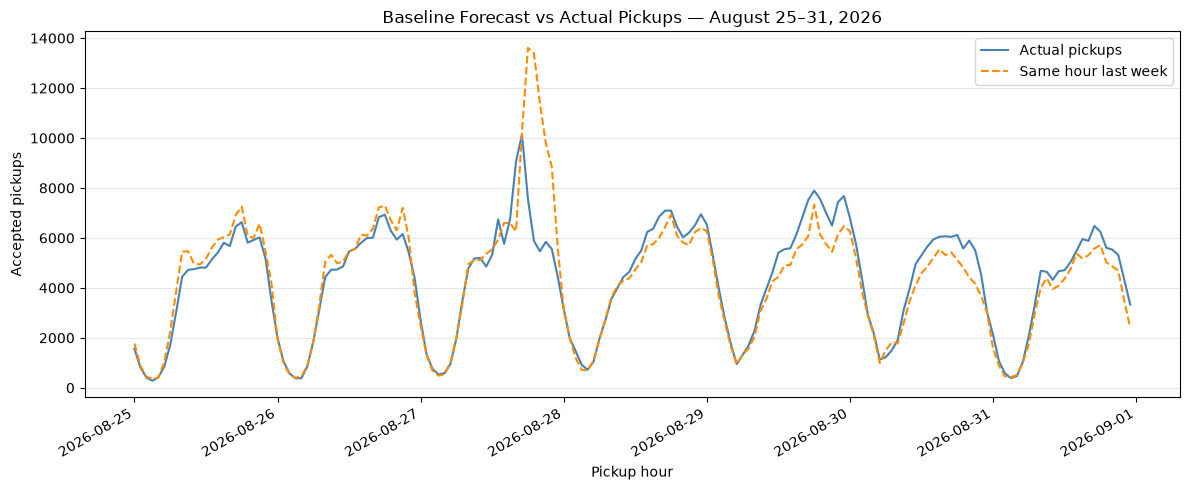

In [143]:
#plotting actual and predicted pickups
fig_baseline, ax_baseline = plt.subplots(
    figsize=(12, 5)
)

ax_baseline.plot(
    baseline_results["pickup_hour"],
    baseline_results["actual_pickups"],
    label="Actual pickups",
    color="steelblue",
    linewidth=1.5
)

ax_baseline.plot(
    baseline_results["pickup_hour"],
    baseline_results["predicted_pickups"],
    label="Same hour last week",
    color="darkorange",
    linestyle="--",
    linewidth=1.5
)

ax_baseline.set_title(
    "Baseline Forecast vs Actual Pickups — August 25–31, 2026"
)
ax_baseline.set_xlabel("Pickup hour")
ax_baseline.set_ylabel("Accepted pickups")
ax_baseline.legend()
ax_baseline.grid(axis="y", alpha=0.3)

fig_baseline.autofmt_xdate()
fig_baseline.tight_layout()

plt.show()

In [144]:
baseline_results.to_csv(
    processed_dir / "baseline_hourly_predictions.csv",
    index=False
)

fig_baseline.savefig(
    chart_dir / "baseline_forecast_vs_actual.png",
    dpi=150,
    bbox_inches="tight"
)

print("Baseline predictions and chart saved.")

Baseline predictions and chart saved.


## 7. Introductory Decision Tree

I trained a small regression tree to learn relationships between
historical features and hourly pickup counts.

This section introduces training, prediction and tree interpretation.
The August test period was inspected during this learning stage.

In [145]:
%pip install scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Raiyan Sulemani\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [146]:
from sklearn.tree import DecisionTreeRegressor

In [147]:
tree_model = DecisionTreeRegressor(
    max_depth=3,
    min_samples_leaf=10,
    random_state=42
)

In [148]:
tree_model.fit(
    X_train,
    y_train
)

print("Decision tree trained.")

Decision tree trained.


In [149]:
tree_predictions = tree_model.predict(
    X_test
)

print(tree_predictions[:10])

[1242.7826087   528.61290323  528.61290323  528.61290323  528.61290323
 1242.7826087  2235.25       3261.22222222 5395.50526316 5395.50526316]


In [150]:
tree_results = baseline_results[
    ["pickup_hour", "actual_pickups", "predicted_pickups"]
].copy()

tree_results = tree_results.rename(
    columns={
        "predicted_pickups": "baseline_prediction"
    }
)

tree_results["tree_prediction"] = tree_predictions

tree_results["tree_absolute_error"] = (
    tree_results["tree_prediction"]
    - tree_results["actual_pickups"]
).abs()

display(tree_results.head(10))

,pickup_hour,actual_pickups,baseline_prediction,tree_prediction,tree_absolute_error
576,2026-08-25 00:00:00,1564,1771.0,1242.782609,321.217391
577,2026-08-25 01:00:00,817,883.0,528.612903,288.387097
578,2026-08-25 02:00:00,412,448.0,528.612903,116.612903
579,2026-08-25 03:00:00,282,358.0,528.612903,246.612903
580,2026-08-25 04:00:00,413,412.0,528.612903,115.612903
581,2026-08-25 05:00:00,838,999.0,1242.782609,404.782609
582,2026-08-25 06:00:00,1710,2250.0,2235.250000,525.250000
583,2026-08-25 07:00:00,3028,3841.0,3261.222222,233.222222
584,2026-08-25 08:00:00,4442,5449.0,5395.505263,953.505263
585,2026-08-25 09:00:00,4722,5463.0,5395.505263,673.505263


In [151]:
tree_mae = tree_results["tree_absolute_error"].mean()

mae_comparison = pd.DataFrame({
    "Method": [
        "Same hour last week",
        "Decision tree"
    ],
    "MAE_pickups_per_hour": [
        baseline_mae,
        tree_mae
    ]
})

display(mae_comparison)

,Method,MAE_pickups_per_hour
0,Same hour last week,571.232143
1,Decision tree,586.303663


In [152]:
from sklearn.tree import export_text

tree_rules = export_text(
    tree_model,
    feature_names=list(X_train.columns),
    decimals=2
)

print(tree_rules)

|--- pickups_lag_168 <= 3960.50
|   |--- pickups_lag_168 <= 1867.00
|   |   |--- pickups_lag_168 <= 883.00
|   |   |   |--- value: [528.61]
|   |   |--- pickups_lag_168 >  883.00
|   |   |   |--- value: [1242.78]
|   |--- pickups_lag_168 >  1867.00
|   |   |--- pickups_lag_168 <= 2916.50
|   |   |   |--- value: [2235.25]
|   |   |--- pickups_lag_168 >  2916.50
|   |   |   |--- value: [3261.22]
|--- pickups_lag_168 >  3960.50
|   |--- pickups_lag_168 <= 6225.50
|   |   |--- pickups_lag_168 <= 5117.50
|   |   |   |--- value: [4425.19]
|   |   |--- pickups_lag_168 >  5117.50
|   |   |   |--- value: [5395.51]
|   |--- pickups_lag_168 >  6225.50
|   |   |--- pickups_lag_1 <= 7615.00
|   |   |   |--- value: [6547.50]
|   |   |--- pickups_lag_1 >  7615.00
|   |   |   |--- value: [9388.40]



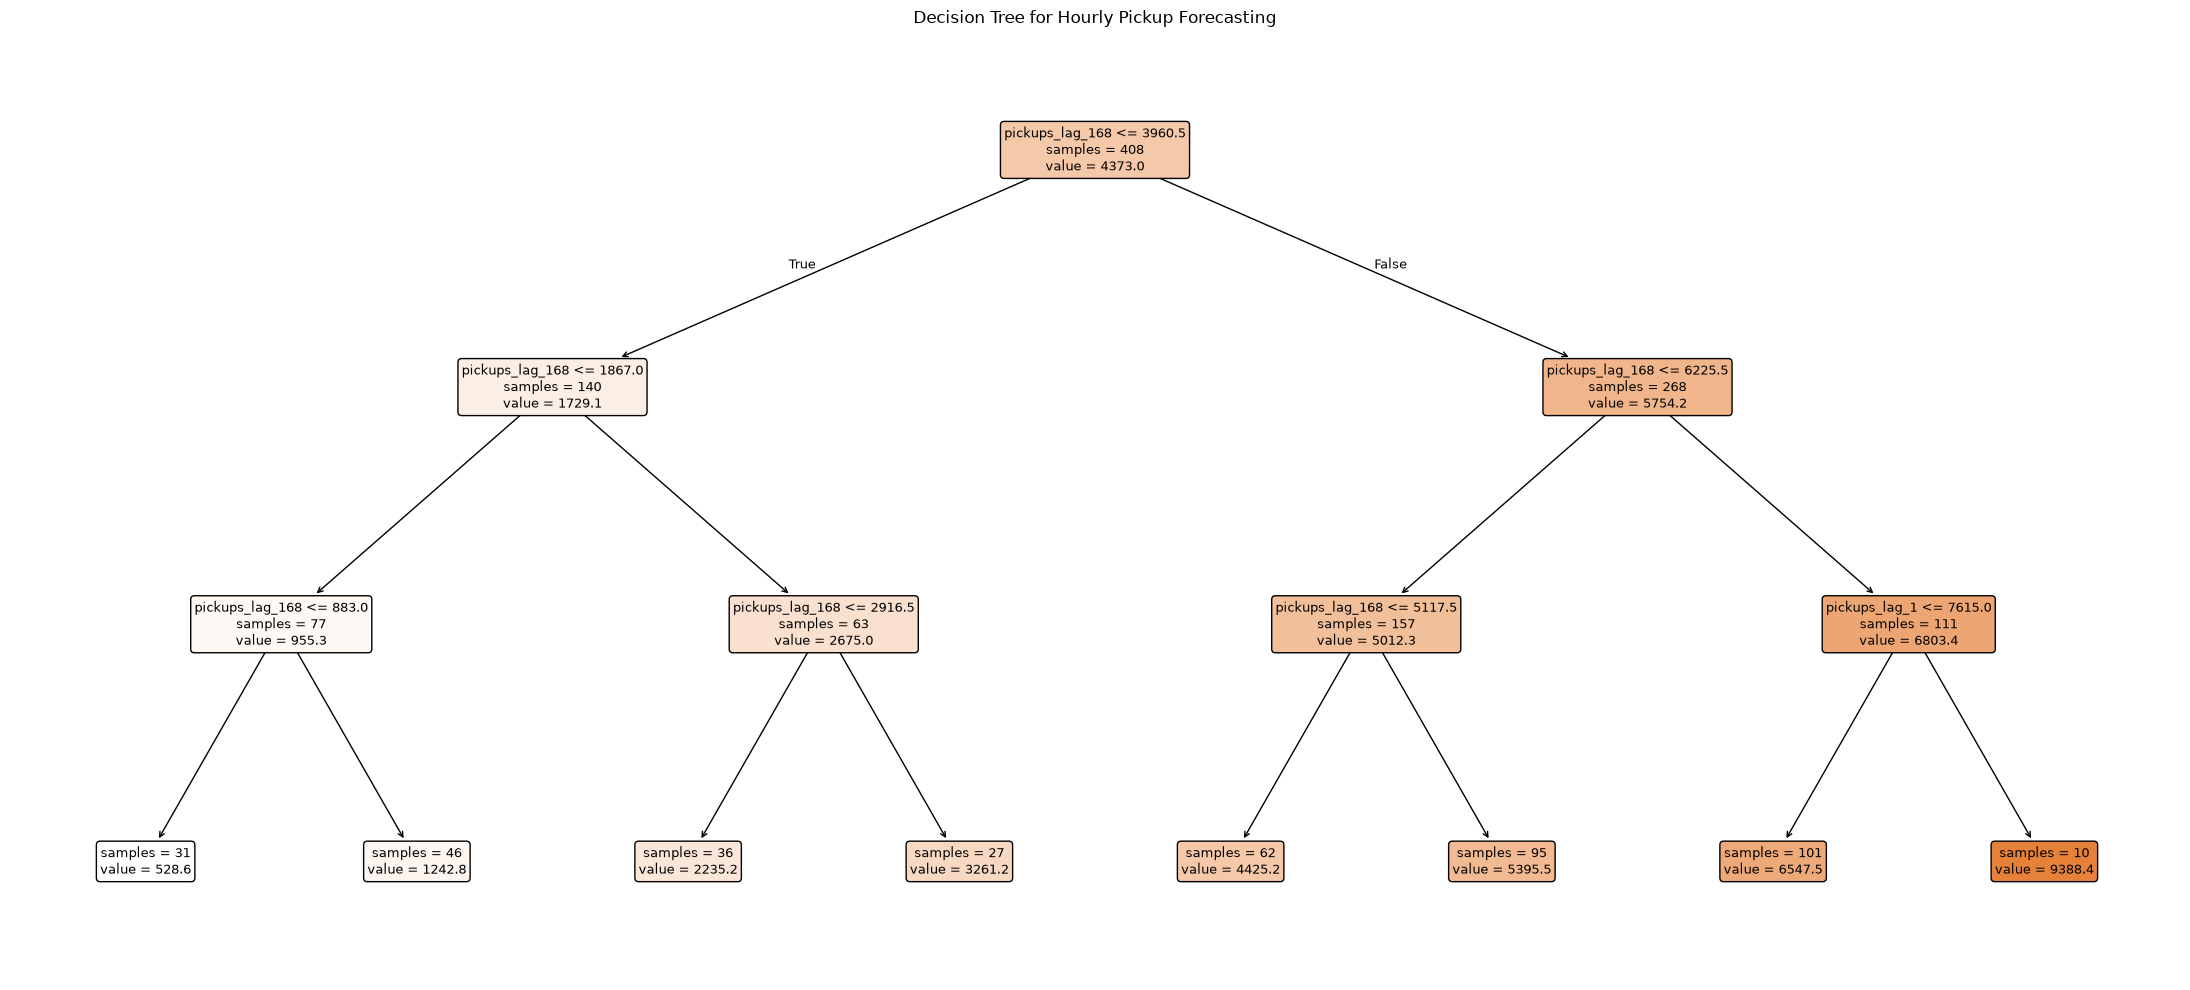

In [153]:
#drawing the plot tree
from sklearn.tree import plot_tree

fig_tree, ax_tree = plt.subplots(
    figsize=(22, 10)
)

plot_tree(
    tree_model,
    feature_names=list(X_train.columns),
    filled=True,
    rounded=True,
    impurity=False,
    precision=1,
    fontsize=9,
    ax=ax_tree
)

ax_tree.set_title("Decision Tree for Hourly Pickup Forecasting")

fig_tree.tight_layout()
plt.show()

In [154]:
#inspecting one hour's inputs and prediction
one_hour = X_test.iloc[[0]]

display(one_hour)

one_prediction = tree_model.predict(one_hour)[0]
one_actual = y_test.iloc[0]

print("Hour:", test_data["pickup_hour"].iloc[0])
print(f"Tree prediction: {one_prediction:,.2f}")
print(f"Actual pickups: {one_actual:,.0f}")
print(f"Absolute error: {abs(one_prediction - one_actual):,.2f}")

,pickups_lag_1,pickups_lag_24,pickups_lag_168,pickups_mean_previous_3h,pickups_mean_previous_24h,hour_of_day,day_of_week,is_weekend
576,2406.0,1571.0,1771.0,3531.666667,3449.0,0,1,0


Hour: 2026-08-25 00:00:00
Tree prediction: 1,242.78
Actual pickups: 1,564
Absolute error: 321.22


In [155]:
#generating the predictions and putting them beside actual count
tree_predictions = tree_model.predict(X_test)

comparison_results = test_data[
    ["pickup_hour", "pickups", "pickups_lag_168"]
].copy()

comparison_results = comparison_results.rename(
    columns={
        "pickups": "actual_pickups",
        "pickups_lag_168": "baseline_prediction"
    }
)

comparison_results["tree_prediction"] = tree_predictions

display(comparison_results.head(10))

,pickup_hour,actual_pickups,baseline_prediction,tree_prediction
576,2026-08-25 00:00:00,1564,1771.0,1242.782609
577,2026-08-25 01:00:00,817,883.0,528.612903
578,2026-08-25 02:00:00,412,448.0,528.612903
579,2026-08-25 03:00:00,282,358.0,528.612903
580,2026-08-25 04:00:00,413,412.0,528.612903
581,2026-08-25 05:00:00,838,999.0,1242.782609
582,2026-08-25 06:00:00,1710,2250.0,2235.250000
583,2026-08-25 07:00:00,3028,3841.0,3261.222222
584,2026-08-25 08:00:00,4442,5449.0,5395.505263
585,2026-08-25 09:00:00,4722,5463.0,5395.505263


In [156]:
#each method's error
comparison_results["baseline_absolute_error"] = (
    comparison_results["baseline_prediction"]
    - comparison_results["actual_pickups"]
).abs()

comparison_results["tree_absolute_error"] = (
    comparison_results["tree_prediction"]
    - comparison_results["actual_pickups"]
).abs()

display(
    comparison_results[
        [
            "pickup_hour",
            "actual_pickups",
            "baseline_absolute_error",
            "tree_absolute_error"
        ]
    ].head(10)
)

,pickup_hour,actual_pickups,baseline_absolute_error,tree_absolute_error
576,2026-08-25 00:00:00,1564,207.0,321.217391
577,2026-08-25 01:00:00,817,66.0,288.387097
578,2026-08-25 02:00:00,412,36.0,116.612903
579,2026-08-25 03:00:00,282,76.0,246.612903
580,2026-08-25 04:00:00,413,1.0,115.612903
581,2026-08-25 05:00:00,838,161.0,404.782609
582,2026-08-25 06:00:00,1710,540.0,525.250000
583,2026-08-25 07:00:00,3028,813.0,233.222222
584,2026-08-25 08:00:00,4442,1007.0,953.505263
585,2026-08-25 09:00:00,4722,741.0,673.505263


In [157]:
#mean aboslute error and weighted absolute percentage error
baseline_mae = (
    comparison_results["baseline_absolute_error"].mean()
)

tree_mae = (
    comparison_results["tree_absolute_error"].mean()
)

total_actual = comparison_results["actual_pickups"].sum()

baseline_wape = (
    100 * comparison_results["baseline_absolute_error"].sum()
    / total_actual
    if total_actual > 0
    else float("nan")
)

tree_wape = (
    100 * comparison_results["tree_absolute_error"].sum()
    / total_actual
    if total_actual > 0
    else float("nan")
)

model_scores = pd.DataFrame({
    "Method": [
        "Same hour last week",
        "Decision tree"
    ],
    "MAE": [
        baseline_mae,
        tree_mae
    ],
    "WAPE_percent": [
        baseline_wape,
        tree_wape
    ]
})

display(model_scores.round(2))

,Method,MAE,WAPE_percent
0,Same hour last week,571.23,13.14
1,Decision tree,586.30,13.49


In [158]:
#measuring the change relative to baseline
if baseline_mae > 0:
    mae_improvement_pct = (
        (baseline_mae - tree_mae)
        / baseline_mae
        * 100
    )

    print(
        f"Tree MAE improvement over baseline: "
        f"{mae_improvement_pct:+.2f}%"
    )
else:
    print(
        "Relative improvement is undefined "
        "because baseline MAE is zero."
    )

Tree MAE improvement over baseline: -2.64%


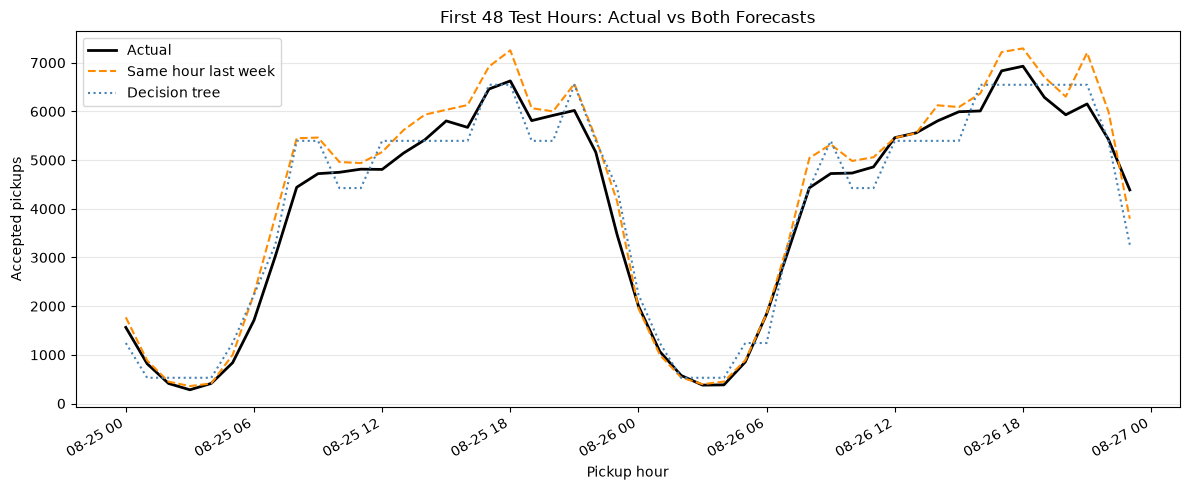

In [159]:
#comparing both forecasts visually
first_48_hours = comparison_results.iloc[:48]

fig_comparison, ax_comparison = plt.subplots(
    figsize=(12, 5)
)

ax_comparison.plot(
    first_48_hours["pickup_hour"],
    first_48_hours["actual_pickups"],
    label="Actual",
    color="black",
    linewidth=2
)

ax_comparison.plot(
    first_48_hours["pickup_hour"],
    first_48_hours["baseline_prediction"],
    label="Same hour last week",
    color="darkorange",
    linestyle="--"
)

ax_comparison.plot(
    first_48_hours["pickup_hour"],
    first_48_hours["tree_prediction"],
    label="Decision tree",
    color="steelblue",
    linestyle=":"
)

ax_comparison.set_title(
    "First 48 Test Hours: Actual vs Both Forecasts"
)
ax_comparison.set_xlabel("Pickup hour")
ax_comparison.set_ylabel("Accepted pickups")
ax_comparison.legend()
ax_comparison.grid(axis="y", alpha=0.3)

fig_comparison.autofmt_xdate()
fig_comparison.tight_layout()

plt.show()

In [160]:
comparison_results.to_csv(
    processed_dir / "baseline_vs_tree_predictions.csv",
    index=False
)

model_scores.to_csv(
    processed_dir / "baseline_vs_tree_scores.csv",
    index=False
)

fig_comparison.savefig(
    chart_dir / "baseline_vs_tree_first_48_hours.png",
    dpi=150,
    bbox_inches="tight"
)

print("Prediction comparison, scores and chart saved.")

Prediction comparison, scores and chart saved.


## 8. Validation and Model Comparison

Training uses August 8–17, while validation uses August 18–24.

I compared decision tree depths and a random forest against the weekly
baseline using validation MAE. The selected approach was then prepared
using the full pre-test period, August 8–24.

In [161]:
#creating training and validating datasets
validation_start = pd.Timestamp("2026-08-18")
validation_end = pd.Timestamp("2026-08-25")

fit_data = model_data.loc[
    model_data["pickup_hour"] < validation_start
].copy()

validation_data = model_data.loc[
    (model_data["pickup_hour"] >= validation_start)
    & (model_data["pickup_hour"] < validation_end)
].copy()

print("Training hours:", len(fit_data))
print("Validation hours:", len(validation_data))

Training hours: 240
Validation hours: 168


In [162]:
X_fit = fit_data[feature_columns]
y_fit = fit_data[target_column]

X_validation = validation_data[feature_columns]
y_validation = validation_data[target_column]

assert len(fit_data) > 0
assert len(validation_data) > 0

assert (
    fit_data["pickup_hour"].max()
    < validation_data["pickup_hour"].min()
)

assert (
    validation_data["pickup_hour"].max()
    < test_data["pickup_hour"].min()
)

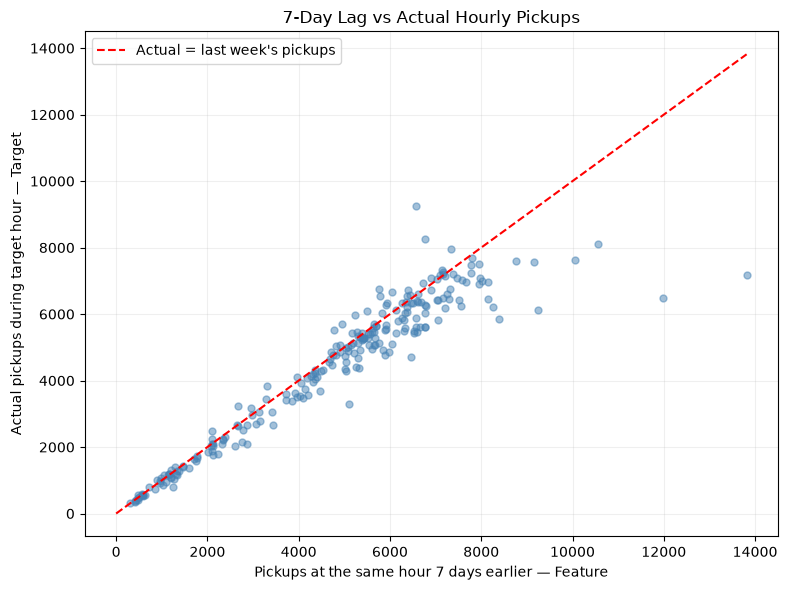

In [204]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    fit_data["pickups_lag_168"],
    fit_data["pickups"], 
    alpha=0.5,
    color="steelblue",
    s=25
)

# Draw the reference line: actual = last week's count
maximum = fit_data[["pickups_lag_168", "pickups"]].max().max()

plt.plot(
    [0, maximum],
    [0, maximum],
    "r--",
    label="Actual = last week's pickups"
)

plt.xlabel("Pickups at the same hour 7 days earlier — Feature")
plt.ylabel("Actual pickups during target hour — Target")
plt.title("7-Day Lag vs Actual Hourly Pickups")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [163]:

#comparing three tree (i.e 2,3,5) depths
validation_records = []

for depth in [2, 3, 5]:

    candidate_model = DecisionTreeRegressor(
        max_depth=depth,
        min_samples_leaf=10,
        random_state=42
    )

    candidate_model.fit(X_fit, y_fit)

    fit_predictions = candidate_model.predict(X_fit)

    validation_predictions = candidate_model.predict(
        X_validation
    )

    training_mae = (
        y_fit.to_numpy() - fit_predictions
    )
    training_mae = abs(training_mae).mean()

    validation_mae = (
        y_validation.to_numpy() - validation_predictions
    )
    validation_mae = abs(validation_mae).mean()

    validation_records.append({
        "max_depth": depth,
        "training_mae": training_mae,
        "validation_mae": validation_mae
    })

validation_scores = pd.DataFrame(validation_records)

display(validation_scores.round(2))

,max_depth,training_mae,validation_mae
0,2,529.03,631.48
1,3,363.57,501.90
2,5,270.19,453.43


In [164]:

ranked_validation_scores = (
    validation_scores
    .sort_values(
        ["validation_mae", "max_depth"]
    )
    .reset_index(drop=True)
)

best_depth = int(
    ranked_validation_scores.loc[0, "max_depth"]
)

display(ranked_validation_scores.round(2))
print("Selected depth:", best_depth)

,max_depth,training_mae,validation_mae
0,5,270.19,453.43
1,3,363.57,501.90
2,2,529.03,631.48


Selected depth: 5


In [165]:
validation_baseline_mae = (
    validation_data["pickups"]
    - validation_data["pickups_lag_168"]
).abs().mean()

print(
    f"Validation baseline MAE: "
    f"{validation_baseline_mae:,.2f}"
)

Validation baseline MAE: 423.03


In [166]:
# retrieving the selected depth
ranked_validation_scores = (
    validation_scores
    .sort_values(
        ["validation_mae", "max_depth"]
    )
    .reset_index(drop=True)
)

best_depth = int(
    ranked_validation_scores.loc[0, "max_depth"]
)

display(ranked_validation_scores.round(2))
print("Selected maximum depth:", best_depth)

,max_depth,training_mae,validation_mae
0,5,270.19,453.43
1,3,363.57,501.90
2,2,529.03,631.48


Selected maximum depth: 5


In [167]:
#creating and training the final selected tree
selected_tree = DecisionTreeRegressor(
    max_depth=best_depth,
    min_samples_leaf=10,
    random_state=42
)

selected_tree.fit(
    X_train,
    y_train
)

print("Selected tree refitted on August 8–24.")

Selected tree refitted on August 8–24.


In [168]:
#predicting the test hours
selected_predictions = selected_tree.predict(
    X_test
)

selected_results = test_data[
    ["pickup_hour", "pickups", "pickups_lag_168"]
].copy()

selected_results = selected_results.rename(
    columns={
        "pickups": "actual_pickups",
        "pickups_lag_168": "baseline_prediction"
    }
)

selected_results["selected_tree_prediction"] = (
    selected_predictions
)

display(selected_results.head(10))

,pickup_hour,actual_pickups,baseline_prediction,selected_tree_prediction
576,2026-08-25 00:00:00,1564,1771.0,1634.400000
577,2026-08-25 01:00:00,817,883.0,676.272727
578,2026-08-25 02:00:00,412,448.0,395.900000
579,2026-08-25 03:00:00,282,358.0,395.900000
580,2026-08-25 04:00:00,413,412.0,395.900000
581,2026-08-25 05:00:00,838,999.0,982.461538
582,2026-08-25 06:00:00,1710,2250.0,2020.153846
583,2026-08-25 07:00:00,3028,3841.0,3475.857143
584,2026-08-25 08:00:00,4442,5449.0,4942.739130
585,2026-08-25 09:00:00,4722,5463.0,4942.739130


In [169]:
#comparing the average error
selected_results["baseline_absolute_error"] = (
    selected_results["baseline_prediction"]
    - selected_results["actual_pickups"]
).abs()

selected_results["tree_absolute_error"] = (
    selected_results["selected_tree_prediction"]
    - selected_results["actual_pickups"]
).abs()

selected_scores = pd.DataFrame({
    "Method": [
        "Same hour last week",
        f"Selected tree: depth {best_depth}"
    ],
    "Test_MAE": [
        selected_results["baseline_absolute_error"].mean(),
        selected_results["tree_absolute_error"].mean()
    ]
})

display(selected_scores.round(2))

,Method,Test_MAE
0,Same hour last week,571.23
1,Selected tree: depth 5,475.60


In [170]:
selected_results.to_csv(
    processed_dir / "selected_tree_test_predictions.csv",
    index=False
)

selected_scores.to_csv(
    processed_dir / "selected_tree_test_scores.csv",
    index=False
)

print("Selected tree predictions and scores saved.")

Selected tree predictions and scores saved.


In [171]:
error_analysis = selected_results.copy()

error_analysis["signed_error"] = (
    error_analysis["selected_tree_prediction"]
    - error_analysis["actual_pickups"]
)

error_analysis["absolute_error"] = (
    error_analysis["signed_error"].abs()
)

display(error_analysis.head())

,pickup_hour,actual_pickups,baseline_prediction,selected_tree_prediction,baseline_absolute_error,tree_absolute_error,signed_error,absolute_error
576,2026-08-25 00:00:00,1564,1771.0,1634.400000,207.0,70.400000,70.400000,70.400000
577,2026-08-25 01:00:00,817,883.0,676.272727,66.0,140.727273,-140.727273,140.727273
578,2026-08-25 02:00:00,412,448.0,395.900000,36.0,16.100000,-16.100000,16.100000
579,2026-08-25 03:00:00,282,358.0,395.900000,76.0,113.900000,113.900000,113.900000
580,2026-08-25 04:00:00,413,412.0,395.900000,1.0,17.100000,-17.100000,17.100000


In [172]:
#error analysis
#calculating whether predictions are too high or too low
error_analysis = selected_results.copy()

error_analysis["signed_error"] = (
    error_analysis["selected_tree_prediction"]
    - error_analysis["actual_pickups"]
)

error_analysis["absolute_error"] = (
    error_analysis["signed_error"].abs()
)

display(error_analysis.head())

,pickup_hour,actual_pickups,baseline_prediction,selected_tree_prediction,baseline_absolute_error,tree_absolute_error,signed_error,absolute_error
576,2026-08-25 00:00:00,1564,1771.0,1634.400000,207.0,70.400000,70.400000,70.400000
577,2026-08-25 01:00:00,817,883.0,676.272727,66.0,140.727273,-140.727273,140.727273
578,2026-08-25 02:00:00,412,448.0,395.900000,36.0,16.100000,-16.100000,16.100000
579,2026-08-25 03:00:00,282,358.0,395.900000,76.0,113.900000,113.900000,113.900000
580,2026-08-25 04:00:00,413,412.0,395.900000,1.0,17.100000,-17.100000,17.100000


In [173]:
#inspecting the 10 largest error
largest_errors = error_analysis.nlargest(
    10,
    "absolute_error"
)

display(
    largest_errors[
        [
            "pickup_hour",
            "actual_pickups",
            "selected_tree_prediction",
            "signed_error",
            "absolute_error"
        ]
    ].round(2)
)

C:\Users\Raiyan Sulemani\AppData\Local\Temp\ipykernel_28532\60012877.py:16: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,pickup_hour,actual_pickups,selected_tree_prediction,signed_error,absolute_error
640,2026-08-27 16:00:00,9054,6293.97,-2760.03,2760.03
696,2026-08-30 00:00:00,6791,9388.40,2597.40,2597.40
642,2026-08-27 18:00:00,7557,9388.40,1831.40,1831.40
716,2026-08-30 20:00:00,5892,4172.81,-1719.19,1719.19
717,2026-08-30 21:00:00,5508,3848.08,-1659.92,1659.92
691,2026-08-29 19:00:00,7557,6034.74,-1522.26,1522.26
689,2026-08-29 17:00:00,7517,6034.74,-1482.26,1482.26
694,2026-08-29 22:00:00,7438,6034.74,-1403.26,1403.26
637,2026-08-27 13:00:00,6743,5355.29,-1387.71,1387.71
695,2026-08-29 23:00:00,7677,6293.97,-1383.03,1383.03


In [174]:
#grouping errors by hour of day, of all test observation
error_analysis["hour_of_day"] = (
    error_analysis["pickup_hour"].dt.hour
)

hourly_error_summary = (
    error_analysis
    .groupby("hour_of_day")
    .agg(
        evaluated_hours=("absolute_error", "size"),
        average_actual_pickups=("actual_pickups", "mean"),
        tree_mae=("absolute_error", "mean"),
        baseline_mae=("baseline_absolute_error", "mean"),
        mean_signed_error=("signed_error", "mean")
    )
    .reset_index()
)

display(hourly_error_summary.round(2))

,hour_of_day,evaluated_hours,average_actual_pickups,tree_mae,baseline_mae,mean_signed_error
0,0,7,3552.00,602.34,264.43,188.56
1,1,7,2477.43,273.70,155.71,-239.34
2,2,7,1737.86,306.06,196.29,-306.06
3,3,7,1175.00,125.49,79.43,-84.43
4,4,7,931.86,57.86,57.57,-45.91
5,5,7,974.29,86.64,67.43,8.18
6,6,7,1730.86,174.21,174.57,-13.56
7,7,7,2697.43,226.58,274.71,-58.80
8,8,7,3726.29,317.30,415.29,-156.59
9,9,7,4240.00,432.63,356.00,-307.07


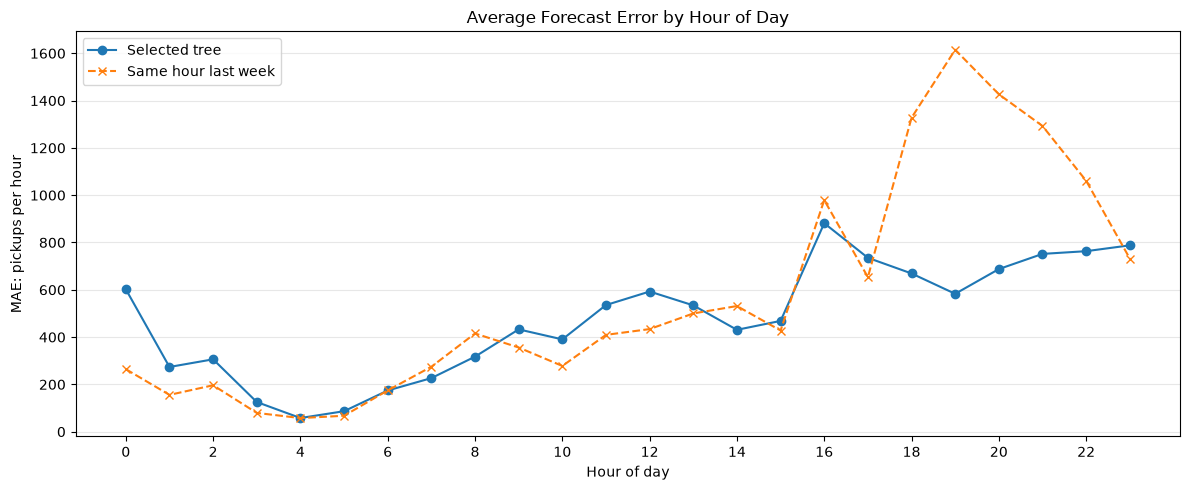

In [175]:
#plot of error by hour
fig_errors, ax_errors = plt.subplots(figsize=(12, 5))

ax_errors.plot(
    hourly_error_summary["hour_of_day"],
    hourly_error_summary["tree_mae"],
    marker="o",
    label="Selected tree"
)

ax_errors.plot(
    hourly_error_summary["hour_of_day"],
    hourly_error_summary["baseline_mae"],
    marker="x",
    linestyle="--",
    label="Same hour last week"
)

ax_errors.set_title("Average Forecast Error by Hour of Day")
ax_errors.set_xlabel("Hour of day")
ax_errors.set_ylabel("MAE: pickups per hour")
ax_errors.set_xticks(range(0, 24, 2))
ax_errors.legend()
ax_errors.grid(axis="y", alpha=0.3)

fig_errors.tight_layout()
plt.show()

In [176]:
largest_errors.to_csv(
    processed_dir / "selected_tree_largest_errors.csv",
    index=False
)

hourly_error_summary.to_csv(
    processed_dir / "selected_tree_errors_by_hour.csv",
    index=False
)

fig_errors.savefig(
    chart_dir / "selected_tree_errors_by_hour.png",
    dpi=150,
    bbox_inches="tight"
)

print("Error analysis tables and chart saved.")

Error analysis tables and chart saved.


In [177]:
#random forest model
#creating the forest
from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=5,
    max_features=0.8,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

In [178]:
#training using the earlier training period
forest_model.fit(
    X_fit,
    y_fit
)

print("Random forest trained.")

Random forest trained.


In [179]:
#predicting the validation hour
forest_validation_predictions = forest_model.predict(
    X_validation
)

forest_validation_results = validation_data[
    ["pickup_hour", "pickups"]
].copy()

forest_validation_results = (
    forest_validation_results.rename(
        columns={"pickups": "actual_pickups"}
    )
)

forest_validation_results["forest_prediction"] = (
    forest_validation_predictions
)

display(forest_validation_results.head(10))

,pickup_hour,actual_pickups,forest_prediction
408,2026-08-18 00:00:00,1771,1685.432116
409,2026-08-18 01:00:00,883,1072.787896
410,2026-08-18 02:00:00,448,505.653389
411,2026-08-18 03:00:00,358,472.873668
412,2026-08-18 04:00:00,412,480.752176
413,2026-08-18 05:00:00,999,724.506107
414,2026-08-18 06:00:00,2250,1941.430192
415,2026-08-18 07:00:00,3841,3250.585879
416,2026-08-18 08:00:00,5449,4550.725613
417,2026-08-18 09:00:00,5463,5145.093276


In [180]:
#calculating validation MAE
forest_validation_results["absolute_error"] = (
    forest_validation_results["forest_prediction"]
    - forest_validation_results["actual_pickups"]
).abs()

forest_validation_mae = (
    forest_validation_results["absolute_error"].mean()
)

print(
    f"Random forest validation MAE: "
    f"{forest_validation_mae:,.2f} pickups per hour"
)

Random forest validation MAE: 351.97 pickups per hour


In [181]:
#comparing all three approaches on validation data
best_tree_validation_mae = (
    validation_scores["validation_mae"].min()
)

validation_baseline_mae = (
    validation_data["pickups"]
    - validation_data["pickups_lag_168"]
).abs().mean()

validation_comparison = pd.DataFrame({
    "Method": [
        "Same hour last week",
        "Best single tree",
        "Random forest"
    ],
    "Validation_MAE": [
        validation_baseline_mae,
        best_tree_validation_mae,
        forest_validation_mae
    ]
})

validation_comparison = (
    validation_comparison
    .sort_values("Validation_MAE")
    .reset_index(drop=True)
)

display(validation_comparison.round(2))

,Method,Validation_MAE
0,Random forest,351.97
1,Same hour last week,423.03
2,Best single tree,453.43


In [182]:
one_hour_features = X_validation.iloc[[0]]

one_hour_time = validation_data["pickup_hour"].iloc[0]
one_hour_actual = y_validation.iloc[0]

print("Hour being predicted:", one_hour_time)
print("Actual pickups:", one_hour_actual)

display(one_hour_features)

Hour being predicted: 2026-08-18 00:00:00
Actual pickups: 1771


,pickups_lag_1,pickups_lag_24,pickups_lag_168,pickups_mean_previous_3h,pickups_mean_previous_24h,hour_of_day,day_of_week,is_weekend
408,3236.0,1800.0,1673.0,3813.333333,3731.916667,0,1,0


In [183]:
#asking every for its prediction
individual_predictions = []

for tree_number, individual_tree in enumerate(
    forest_model.estimators_,
    start=1
):
    prediction = individual_tree.predict(
        one_hour_features.to_numpy()
    )[0]

    individual_predictions.append({
        "tree_number": tree_number,
        "predicted_pickups": prediction
    })

tree_predictions_table = pd.DataFrame(
    individual_predictions
)

display(tree_predictions_table.head(10))

,tree_number,predicted_pickups
0,1,2119.000000
1,2,1622.500000
2,3,932.166667
3,4,1740.428571
4,5,3347.250000
5,6,2415.428571
6,7,1318.916667
7,8,903.857143
8,9,1773.000000
9,10,2889.083333


In [184]:
#averaging the individual prediction
average_tree_prediction = (
    tree_predictions_table["predicted_pickups"].mean()
)

forest_prediction = forest_model.predict(
    one_hour_features
)[0]

print(
    f"Average of individual trees: "
    f"{average_tree_prediction:,.4f}"
)

print(
    f"Forest prediction: "
    f"{forest_prediction:,.4f}"
)

Average of individual trees: 1,685.4321
Forest prediction: 1,685.4321


In [185]:
import numpy as np

assert np.isclose(
    average_tree_prediction,
    forest_prediction
)

print("Verified: the forest prediction equals the trees' average.")

Verified: the forest prediction equals the trees' average.


In [186]:
#examining the disagreement of trees
display(
    tree_predictions_table["predicted_pickups"]
    .describe()
    .round(2)
)

count     100.00
mean     1685.43
std       470.27
min       903.86
25%      1370.31
50%      1574.21
75%      1909.58
max      3347.25
Name: predicted_pickups, dtype: float64

In [187]:
one_hour_error = forest_prediction - one_hour_actual

print(f"Actual pickups: {one_hour_actual:,.0f}")
print(f"Predicted pickups: {forest_prediction:,.2f}")
print(f"Signed error: {one_hour_error:+,.2f}")
print(f"Absolute error: {abs(one_hour_error):,.2f}")

Actual pickups: 1,771
Predicted pickups: 1,685.43
Signed error: -85.57
Absolute error: 85.57


## 9. Selected Approach Evaluation

The validation-selected approach is evaluated on August 25–31.

I compare predictions with actual counts and the weekly baseline,
then inspect average errors and systematic overprediction or
underprediction.

Because this test period was inspected earlier during development,
these results are exploratory. A stronger evaluation requires an
additional chronological period excluded from development decisions.

In [188]:
ranked_methods = (
    validation_comparison
    .sort_values("Validation_MAE")
    .reset_index(drop=True)
)

winning_method = ranked_methods.loc[0, "Method"]

display(ranked_methods.round(2))
print("Selected approach:", winning_method)

,Method,Validation_MAE
0,Random forest,351.97
1,Same hour last week,423.03
2,Best single tree,453.43


Selected approach: Random forest


In [189]:
#refitting the selected approach
from sklearn.base import clone

if winning_method == "Random forest":
    final_model = clone(forest_model)
    final_model.fit(X_train, y_train)

elif winning_method == "Best single tree":
    final_model = DecisionTreeRegressor(
        max_depth=best_depth,
        min_samples_leaf=10,
        random_state=42
    )
    final_model.fit(X_train, y_train)

else:
    final_model = None

print("Selected approach prepared.")

Selected approach prepared.


In [190]:
#predicting the test hours
if final_model is None:
    final_predictions = X_test[
        "pickups_lag_168"
    ].to_numpy()

else:
    final_predictions = final_model.predict(X_test)

final_results = test_data[
    ["pickup_hour", "pickups", "pickups_lag_168"]
].copy()

final_results = final_results.rename(
    columns={
        "pickups": "actual_pickups",
        "pickups_lag_168": "baseline_prediction"
    }
)

final_results["selected_prediction"] = final_predictions

display(final_results.head(10))

,pickup_hour,actual_pickups,baseline_prediction,selected_prediction
576,2026-08-25 00:00:00,1564,1771.0,1623.903935
577,2026-08-25 01:00:00,817,883.0,848.407165
578,2026-08-25 02:00:00,412,448.0,445.158033
579,2026-08-25 03:00:00,282,358.0,428.343056
580,2026-08-25 04:00:00,413,412.0,443.348520
581,2026-08-25 05:00:00,838,999.0,988.306850
582,2026-08-25 06:00:00,1710,2250.0,2033.831234
583,2026-08-25 07:00:00,3028,3841.0,3063.136970
584,2026-08-25 08:00:00,4442,5449.0,4587.340140
585,2026-08-25 09:00:00,4722,5463.0,4853.973651


In [191]:
#calculating the test errors
final_results["selected_error"] = (
    final_results["selected_prediction"]
    - final_results["actual_pickups"]
)

final_results["selected_absolute_error"] = (
    final_results["selected_error"].abs()
)

final_results["baseline_absolute_error"] = (
    final_results["baseline_prediction"]
    - final_results["actual_pickups"]
).abs()

final_mae = (
    final_results["selected_absolute_error"].mean()
)

baseline_test_mae = (
    final_results["baseline_absolute_error"].mean()
)

final_mean_signed_error = (
    final_results["selected_error"].mean()
)

print("Selected approach:", winning_method)
print(f"Selected approach MAE: {final_mae:,.2f}")
print(f"Baseline MAE: {baseline_test_mae:,.2f}")
print(f"Mean signed error: {final_mean_signed_error:+,.2f}")

Selected approach: Random forest
Selected approach MAE: 414.04
Baseline MAE: 571.23
Mean signed error: -230.82


In [192]:
#improvement over the baseline
if baseline_test_mae > 0:
    improvement_pct = (
        (baseline_test_mae - final_mae)
        / baseline_test_mae
        * 100
    )

    print(
        f"Test MAE improvement over baseline: "
        f"{improvement_pct:+.2f}%"
    )

else:
    improvement_pct = float("nan")

    print(
        "Relative improvement is undefined "
        "because baseline MAE is zero."
    )

Test MAE improvement over baseline: +27.52%


In [193]:
#saving the summary and the prediction
final_summary = pd.DataFrame([{
    "selected_method": winning_method,
    "test_hours": len(final_results),
    "selected_test_mae": final_mae,
    "baseline_test_mae": baseline_test_mae,
    "mae_improvement_pct": improvement_pct,
    "mean_signed_error": final_mean_signed_error
}])

final_summary.to_csv(
    processed_dir / "selected_approach_summary.csv",
    index=False
)

final_results.to_csv(
    processed_dir / "selected_approach_predictions.csv",
    index=False
)

display(final_summary.round(2))

,selected_method,test_hours,selected_test_mae,baseline_test_mae,mae_improvement_pct,mean_signed_error
0,Random forest,168,414.04,571.23,27.52,-230.82


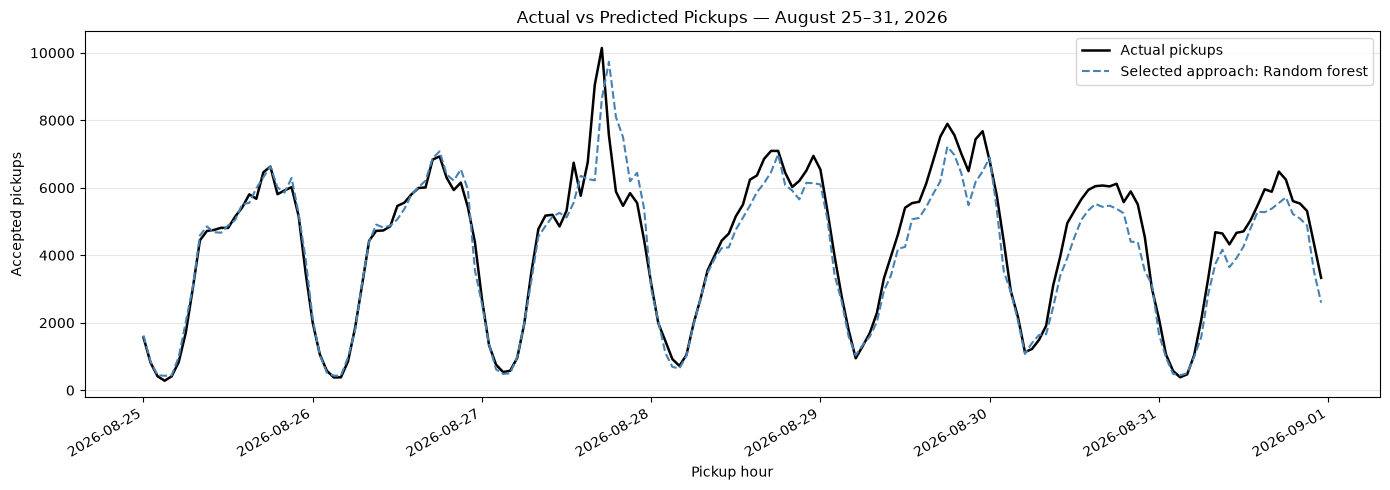

In [194]:
#plotting the full test week 
fig_final, ax_final = plt.subplots(figsize=(14, 5))

ax_final.plot(
    final_results["pickup_hour"],
    final_results["actual_pickups"],
    label="Actual pickups",
    color="black",
    linewidth=1.8
)

ax_final.plot(
    final_results["pickup_hour"],
    final_results["selected_prediction"],
    label=f"Selected approach: {winning_method}",
    color="steelblue",
    linestyle="--",
    linewidth=1.5
)

ax_final.set_title(
    "Actual vs Predicted Pickups — August 25–31, 2026"
)
ax_final.set_xlabel("Pickup hour")
ax_final.set_ylabel("Accepted pickups")
ax_final.legend()
ax_final.grid(axis="y", alpha=0.3)

fig_final.autofmt_xdate()
fig_final.tight_layout()

plt.show()

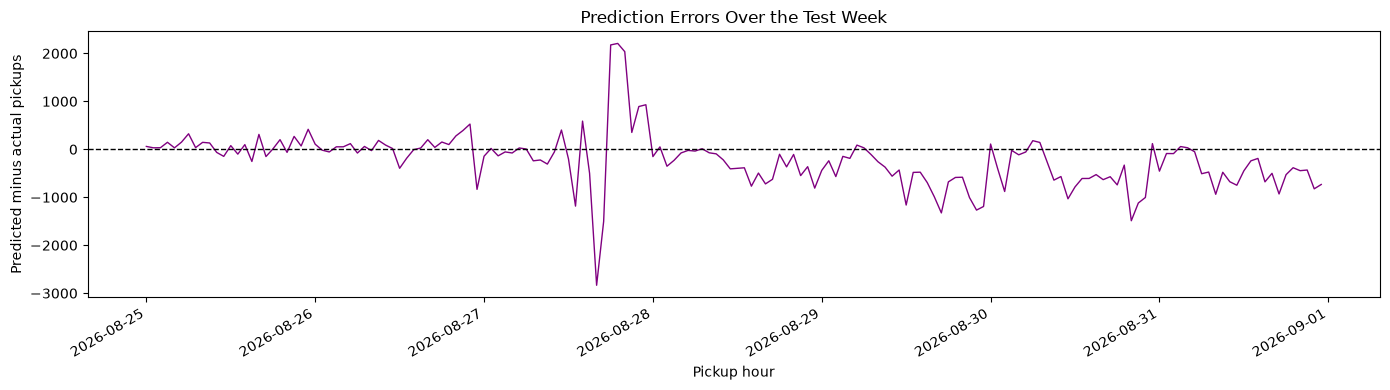

In [195]:
#plotting the signed errors separately
fig_residuals, ax_residuals = plt.subplots(
    figsize=(14, 4)
)

ax_residuals.plot(
    final_results["pickup_hour"],
    final_results["selected_error"],
    color="purple",
    linewidth=1
)

ax_residuals.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax_residuals.set_title(
    "Prediction Errors Over the Test Week"
)
ax_residuals.set_xlabel("Pickup hour")
ax_residuals.set_ylabel("Predicted minus actual pickups")

fig_residuals.autofmt_xdate()
fig_residuals.tight_layout()

plt.show()

In [196]:
#generating a results statement from actual scores
results_statement = (
    f"Selected approach: {winning_method}.\n"
    f"Evaluation period: August 25–31, 2026 "
    f"({len(final_results)} hourly predictions).\n"
    f"Selected approach MAE: {final_mae:,.2f} "
    f"pickups per hour.\n"
    f"Same-hour-last-week baseline MAE: "
    f"{baseline_test_mae:,.2f} pickups per hour.\n"
    f"Mean signed error: "
    f"{final_mean_signed_error:+,.2f} pickups per hour."
)

print(results_statement)

Selected approach: Random forest.
Evaluation period: August 25–31, 2026 (168 hourly predictions).
Selected approach MAE: 414.04 pickups per hour.
Same-hour-last-week baseline MAE: 571.23 pickups per hour.
Mean signed error: -230.82 pickups per hour.


In [197]:
fig_final.savefig(
    chart_dir / "selected_approach_actual_vs_predicted.png",
    dpi=150,
    bbox_inches="tight"
)

fig_residuals.savefig(
    chart_dir / "selected_approach_errors_over_time.png",
    dpi=150,
    bbox_inches="tight"
)

print("Both evaluation charts saved.")

Both evaluation charts saved.


### Evaluation limitations

The August test period was inspected during project development.
Its scores are exploratory rather than a completely untouched final
evaluation.

The study covers one month and cannot establish performance across
seasons. A stronger evaluation requires additional chronological data
held aside from model and feature decisions.

Recorded pickups do not measure unmet requests or driver availability.

### PROJECT PACKAGING

In [198]:
# Create the destination folder if necessary
processed_dir = project_dir / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

# Save the modelling dataset
model_data.to_csv(
    processed_dir / "hourly_model_data.csv",
    index=False,
    date_format="%Y-%m-%d %H:%M:%S"
)

print("Saved to:", (processed_dir / "hourly_model_data.csv").resolve())

Saved to: C:\Users\Raiyan Sulemani\urban-mobility-analytics\data\processed\hourly_model_data.csv


In [199]:
notebook_dir = project_dir / "notebooks"
dashboard_dir = project_dir / "powerbi"

notebook_dir.mkdir(parents=True, exist_ok=True)
dashboard_dir.mkdir(parents=True, exist_ok=True)

print("Notebook folder:", notebook_dir.resolve())
print("Dashboard folder:", dashboard_dir.resolve())

Notebook folder: C:\Users\Raiyan Sulemani\urban-mobility-analytics\notebooks
Dashboard folder: C:\Users\Raiyan Sulemani\urban-mobility-analytics\powerbi


In [200]:
from importlib.metadata import version

packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "pyarrow",
    "scikit-learn"
]

requirements_text = "\n".join(
    f"{package}=={version(package)}"
    for package in packages
)

requirements_path = project_dir / "requirements.txt"

requirements_path.write_text(
    requirements_text + "\n",
    encoding="utf-8"
)

print(requirements_text)

pandas==3.0.6
numpy==2.5.3
matplotlib==3.11.2
pyarrow==26.0.0
scikit-learn==1.9.1


In [201]:
gitignore_text = """\
.ipynb_checkpoints/
__pycache__/
.venv/
venv/
.env

# Raw trip data and local database
*.parquet
*.db
*.db-journal
data/raw/

# Generated modelling dataset
data/processed/hourly_model_data.csv
"""

gitignore_path = project_dir / ".gitignore"

gitignore_path.write_text(
    gitignore_text,
    encoding="utf-8"
)

print("Created:", gitignore_path.resolve())

Created: C:\Users\Raiyan Sulemani\urban-mobility-analytics\.gitignore


In [202]:
for item in sorted(project_dir.iterdir()):
    item_type = "Folder" if item.is_dir() else "File"
    print(f"{item_type}: {item.name}")

File: .gitignore
Folder: .ipynb_checkpoints
File: 01_data_understanding-Copy1.ipynb
Folder: data
Folder: images
Folder: notebooks
Folder: powerbi
File: README.md
File: requirements.txt
File: taxi_zone_lookup.csv
File: Untitled.ipynb
File: Untitled1.ipynb
File: yellow_tripdata_2026-08.parquet


In [203]:
readme_text = f"""\
# NYC Yellow Taxi Analytics and Hourly Pickup Forecasting

## Overview

This project analyses August 2026 NYC yellow taxi records and explores
forecasting accepted pickups one hour ahead across recognised pickup zones.

It combines Python data preparation, SQL analysis, Power BI reporting
and introductory machine learning.

## Tools

- Python, Pandas and NumPy
- Matplotlib
- SQLite
- Power BI and DAX
- Scikit-learn

## Data Source

NYC Taxi and Limousine Commission trip records:

https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page

Files used:
- yellow_tripdata_2026-08.parquet
- taxi_zone_lookup.csv

Raw trip data is excluded from this repository.

## Data Preparation

- Restricted pickup timestamps to August 2026.
- Excluded unrecognised pickup zone codes from the study.
- Retained accepted pickups for activity counts.
- Applied separate screening rules for fare, distance and duration metrics.
- Created daily zone aggregates and calendar and zone lookup tables.

The notebook documents the screening thresholds.

## Analytics and Dashboard

- Daily and hourly pickup patterns
- Weekday and weekend comparisons
- Borough summaries and busiest pickup zones
- SQL joins, aggregations and window functions
- Power BI measures, charts and interactive filters

## Forecasting

Target: accepted pickups during the hour being predicted.

Inputs include:
- Previous hour's pickups
- Same hour yesterday
- Same hour seven days earlier
- Previous 3-hour and 24-hour pickup averages
- Target hour, weekday and weekend indicator

Lag and rolling features use earlier pickup counts only.

Methods compared:
- Same-hour-last-week baseline
- Decision tree
- Random forest

## Evaluation Design

- Initial training: August 8–17
- Validation: August 18–24
- Existing test period: August 25–31

The validation-selected trained model was refitted on August 8–24.
If the baseline was selected, no fitting was required.

## Exploratory Results

- Validation-selected approach: {winning_method}
- Test MAE: {final_mae:,.2f} pickups per hour
- Weekly baseline test MAE: {baseline_test_mae:,.2f} pickups per hour
- Mean signed error: {final_mean_signed_error:+,.2f} pickups per hour

MAE measures average absolute error. Signed error is prediction minus
actual, so a positive mean indicates overprediction on average.

## How to Run

1. Install the packages listed in requirements.txt.
2. Download the trip data and zone lookup from the source above.
3. Open notebooks/urban_mobility_analysis.ipynb.
4. Set project_dir to your local project folder.
5. Check the data-loading paths against your downloaded file locations.
6. Run the notebook cells in order.
7. Open the Power BI report and update its CSV source paths if necessary.

## Limitations

- This is a one-month learning exercise.
- The test period was inspected during development, so its scores are
  exploratory rather than an untouched final evaluation.
- Evaluation assumes earlier hours' counts are available and finalised
  before the next hour is predicted.
- Public monthly files do not provide a live forecasting feed.
- Recorded pickups do not measure unmet requests or driver availability.
- Screening bounds are project assumptions.
- Further chronological data is needed for a stronger evaluation.
"""

readme_path = project_dir / "README.md"

readme_path.write_text(
    readme_text,
    encoding="utf-8"
)

print("README saved to:", readme_path.resolve())

README saved to: C:\Users\Raiyan Sulemani\urban-mobility-analytics\README.md
